In [ ]:
# --- Prepended setup cell: environment, common imports, and helper directories ---
import os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(exist_ok=True)
print("Prep environment ready. Figures will be saved to:", FIG_DIR.resolve())
# This notebook preserves your friend's original notebook exactly, then appends plotting/visualization cells copied from your notebook.


Prep environment ready. Figures will be saved to: /content/figures


In [ ]:
'''Online Retail Analytics – Final Comprehensive Analysis

Business Theme: Inventory Optimization & Customer Retention Strategy

This notebook analyzes a real-world online retail dataset to:
- Clean and explore transaction data
- Visualize geographic and temporal sales patterns
- Build RFM-based customer segments
- Statistically test key business hypotheses (H1–H5)
- Cluster customers into behavioral groups
- Predict which customers are likely to return in the next 3 months '''


'Online Retail Analytics – Final Comprehensive Analysis\n\nBusiness Theme: Inventory Optimization & Customer Retention Strategy\n\nThis notebook analyzes a real-world online retail dataset to:\n- Clean and explore transaction data\n- Visualize geographic and temporal sales patterns\n- Build RFM-based customer segments\n- Statistically test key business hypotheses (H1–H5)\n- Cluster customers into behavioral groups\n- Predict which customers are likely to return in the next 3 months '

In [ ]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import datetime as dt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, roc_curve
import plotly.express as px
import os

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Create output directories
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

print("="*80)
print("ONLINE RETAIL ANALYTICS - FINAL ANALYSIS")
print("Business Theme: Inventory Optimization & Customer Retention Strategy")
print("="*80)


ONLINE RETAIL ANALYTICS - FINAL ANALYSIS
Business Theme: Inventory Optimization & Customer Retention Strategy


In [ ]:
'''1. Data Loading and Cleaning

We first load the Online Retail dataset, inspect basic data quality, remove duplicates,
and create a clean **sales dataset** with only valid, positive-quantity transactions.'''

'1. Data Loading and Cleaning\n\nWe first load the Online Retail dataset, inspect basic data quality, remove duplicates,\nand create a clean **sales dataset** with only valid, positive-quantity transactions.'

In [ ]:
print("\n" + "="*80)
print("SECTION 1: DATA LOADING AND CLEANING")
print("="*80)

# Load data
try:
    df = pd.read_excel('Online Retail.xlsx')
except FileNotFoundError:
    print("Error: 'Online_Retail.xlsx' not found. Please ensure file is in directory.")
    raise

# --- Data Quality Report ---
print("\n--- Data Quality Report ---")
print(f"Total rows: {len(df):,}")
print(f"Missing CustomerID: {df['CustomerID'].isna().sum():,} ({df['CustomerID'].isna().sum()/len(df)*100:.2f}%)")
print(f"Missing Description: {df['Description'].isna().sum():,}")
print(f"Negative Quantity (returns): {(df['Quantity'] < 0).sum():,}")
print(f"Unique products: {df['StockCode'].nunique():,}")
print(f"Countries: {df['Country'].nunique()}")

# Data Cleaning
df.drop_duplicates(inplace=True)
df_clean = df.dropna(subset=['CustomerID'])

# Create Sales Dataset (Positive quantities only) for General Analysis
df_sales = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)].copy()

# Feature Engineering
df_sales['TotalAmount'] = df_sales['Quantity'] * df_sales['UnitPrice']
df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])
df_sales['Date'] = df_sales['InvoiceDate'].dt.date
df_sales['Month'] = df_sales['InvoiceDate'].dt.month
df_sales['Year'] = df_sales['InvoiceDate'].dt.year
df_sales['DayOfWeek'] = df_sales['InvoiceDate'].dt.day_name()

print(f"\nFinal clean dataset for sales analysis: {df_sales.shape}")
df_sales.head()


SECTION 1: DATA LOADING AND CLEANING
Error: 'Online_Retail.xlsx' not found. Please ensure file is in directory.


FileNotFoundError: [Errno 2] No such file or directory: 'Online Retail.xlsx'

In [ ]:
'''2. Enhanced Data Visualization

We explore:
- Geographic revenue distribution across countries
- Temporal revenue patterns using daily sales and 30-day moving average'''

'2. Enhanced Data Visualization\n\nWe explore:\n- Geographic revenue distribution across countries\n- Temporal revenue patterns using daily sales and 30-day moving average'


SECTION 2: ENHANCED DATA VISUALIZATION


✓ Geographic revenue map created


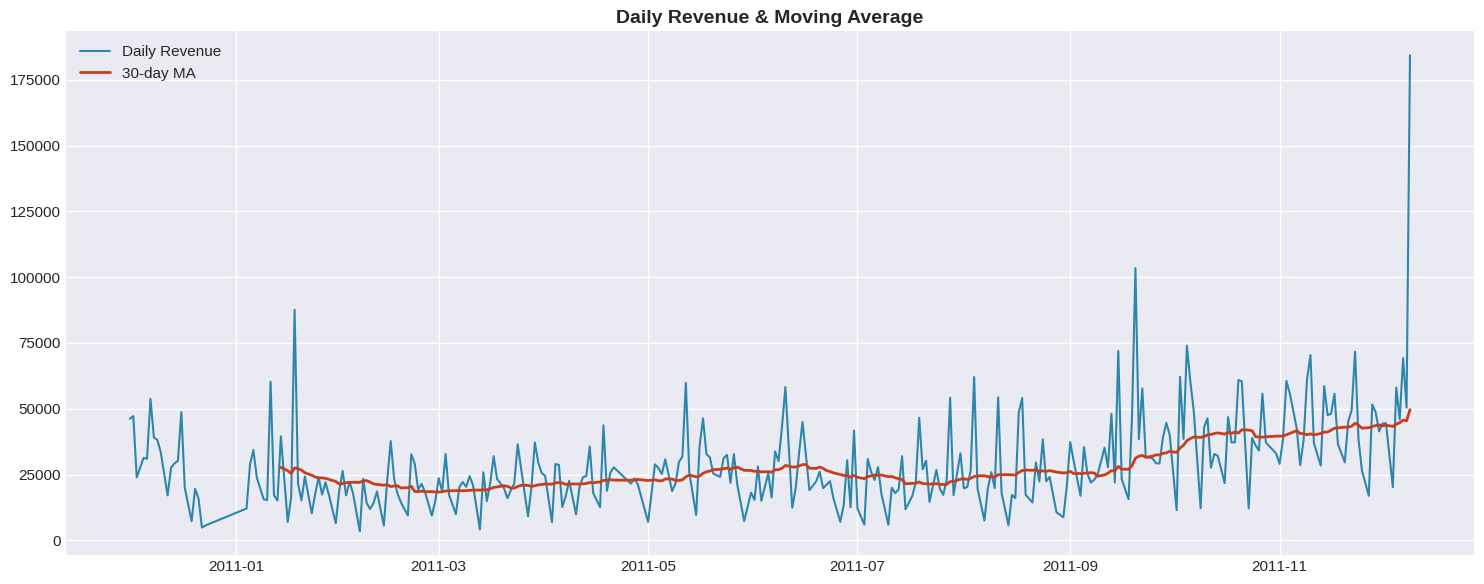

✓ Time series analysis created


In [ ]:
print("\n" + "="*80)
print("SECTION 2: ENHANCED DATA VISUALIZATION")
print("="*80)

# 2.1 Geographic Visualization
country_sales = df_sales.groupby('Country').agg({
    'TotalAmount': 'sum'
}).reset_index().sort_values('TotalAmount', ascending=False)

fig = px.choropleth(
    country_sales,
    locations='Country',
    locationmode='country names',
    color='TotalAmount',
    title='Global Revenue Distribution',
    color_continuous_scale='Viridis'
)
fig.show()
fig.write_html('figures/geographic_revenue_map.html')
print("✓ Geographic revenue map created")

# 2.2 Time Series Analysis
daily_sales = df_sales.groupby('Date')['TotalAmount'].sum().reset_index()
daily_sales.set_index('Date', inplace=True)

plt.figure(figsize=(15, 6))
plt.plot(daily_sales.index, daily_sales['TotalAmount'], color='#2E86AB', label='Daily Revenue')
plt.plot(
    daily_sales.index,
    daily_sales['TotalAmount'].rolling(window=30).mean(),
    color='#C73E1D',
    linewidth=2,
    label='30-day MA'
)
plt.title('Daily Revenue & Moving Average', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('figures/time_series_analysis.png', dpi=300)
plt.show()
print("✓ Time series analysis created")

top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_countries, x='TotalAmount', y='Country', palette='viridis')
plt.title('Top 10 Countries by Total Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('figures/top10_countries_revenue.png', dpi=300)
plt.show()

print("✓ Top 10 revenue countries visualized")

monthly_sales = df_sales.groupby(['Year', 'Month'])['TotalAmount'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['Year'].astype(str) + '-' + monthly_sales['Month'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_sales, x='YearMonth', y='TotalAmount', marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Revenue Trend (Seasonality Highlight)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.tight_layout()
plt.savefig('figures/monthly_revenue_trend.png', dpi=300)
plt.show()

print("✓ Monthly seasonal sales trend created")



In [ ]:
'''3. RFM Analysis and Customer Segmentation

We compute:
- **Recency** (days since last purchase)
- **Frequency** (number of invoices)
- **Monetary** (total spend)

Then we build an RFM score and map customers to segments like **Champions**, **Loyal**, **At Risk**, etc.'''

'3. RFM Analysis and Customer Segmentation\n\nWe compute:\n- **Recency** (days since last purchase)  \n- **Frequency** (number of invoices)  \n- **Monetary** (total spend)\n\nThen we build an RFM score and map customers to segments like **Champions**, **Loyal**, **At Risk**, etc.'

In [ ]:
print("\n" + "="*80)
print("SECTION 3: RFM ANALYSIS")
print("="*80)

latest_date = df_sales['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = df_sales.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (latest_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# Segmentation Logic
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])
rfm['RFM_Sum'] = rfm['R_Score'].astype(int) + rfm['F_Score'].astype(int) + rfm['M_Score'].astype(int)

def segment_customer(score):
    if score >= 9:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 6:
        return 'Potential Loyalists'
    elif score >= 5:
        return 'At Risk'
    else:
        return 'Hibernating/Lost'

rfm['Segment'] = rfm['RFM_Sum'].apply(segment_customer)
print(rfm['Segment'].value_counts())

rfm.head()

plt.figure(figsize=(8, 8))
rfm['Segment'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=sns.color_palette('husl'))
plt.title('Customer Segment Distribution')
plt.ylabel('')
plt.tight_layout()
plt.savefig('figures/rfm_segment_pie.png', dpi=300)
plt.show()

print("✓ Customer segment distribution chart created")




SECTION 3: RFM ANALYSIS
Segment
Champions              1677
Potential Loyalists     935
Hibernating/Lost        806
At Risk                 485
Loyal Customers         435
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Sum,Segment
0,12346.0,326,1,77183.60,1,1,4,6,Potential Loyalists
1,12347.0,2,7,4310.00,4,4,4,12,Champions
2,12348.0,75,4,1797.24,2,3,4,9,Champions
3,12349.0,19,1,1757.55,3,1,4,8,Loyal Customers
4,12350.0,310,1,334.40,1,1,2,4,Hibernating/Lost


In [ ]:
'''4. Statistical Hypothesis Testing (H1 – H5)

We test five business hypotheses:

- **H1:** High-frequency customers have higher monetary value
- **H2:** Repeat customers have higher average order value than single-purchase customers
- **H3:** Transaction amounts differ by day of week
- **H4:** International customers have higher order value than UK customers
- **H5:** Return rates differ significantly across countries
'''

'4. Statistical Hypothesis Testing (H1 – H5)\n\nWe test five business hypotheses:\n\n- **H1:** High-frequency customers have higher monetary value  \n- **H2:** Repeat customers have higher average order value than single-purchase customers  \n- **H3:** Transaction amounts differ by day of week  \n- **H4:** International customers have higher order value than UK customers  \n- **H5:** Return rates differ significantly across countries  \n'

In [ ]:
print("\n" + "="*80)
print("SECTION 4: STATISTICAL HYPOTHESIS TESTING")
print("="*80)

# --- H1: Frequency-Monetary Relationship ---
print("\n--- H1: High-frequency vs Low-frequency Monetary Value ---")
median_freq = rfm['Frequency'].median()
high_freq = rfm[rfm['Frequency'] >= median_freq]['Monetary']
low_freq = rfm[rfm['Frequency'] < median_freq]['Monetary']
t_stat, p_val = stats.ttest_ind(high_freq, low_freq)
print(f"High Freq Mean: £{high_freq.mean():.2f} | Low Freq Mean: £{low_freq.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4e}")
print(f"Result: {'REJECT' if p_val < 0.05 else 'FAIL TO REJECT'} null hypothesis")

# --- H2: Repeat vs Single Purchase Average Order Value (MATCHING REPORT) ---
print("\n--- H2: Repeat vs Single Purchase Average Order Value ---")

# Average value of line items per customer
customer_stats = df_sales.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'TotalAmount': 'mean'  # average line-item value (Quantity * UnitPrice)
}).reset_index()

customer_stats.columns = ['CustomerID', 'NumOrders', 'AvgLineValue']

repeat_customers = customer_stats[customer_stats['NumOrders'] > 1]['AvgLineValue']
single_customers = customer_stats[customer_stats['NumOrders'] == 1]['AvgLineValue']

t_stat, p_val = stats.ttest_ind(repeat_customers, single_customers)
print(f"Repeat customers avg value: £{repeat_customers.mean():.2f} (n={len(repeat_customers):,} customers)")
print(f"Single customers avg value: £{single_customers.mean():.2f} (n={len(single_customers):,} customers)")
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")
print(f"Result: {'REJECT' if p_val < 0.05 else 'FAIL TO REJECT'} null hypothesis")

# --- H3: Weekly Transaction Patterns ---
print("\n--- H3: Weekly Transaction Patterns (ANOVA) ---")
present_days = df_sales['DayOfWeek'].unique()
day_groups = []
valid_days = []

for d in present_days:
    group_data = df_sales[df_sales['DayOfWeek'] == d]['TotalAmount']
    if len(group_data) > 10:
        day_groups.append(group_data)
        valid_days.append(d)

print(f"Days included in ANOVA: {valid_days}")

if len(day_groups) >= 2:
    f_stat, p_val = stats.f_oneway(*day_groups)
    print(f"F-statistic: {f_stat:.4f}, P-value: {p_val:.4e}")
    print(f"Result: {'REJECT' if p_val < 0.05 else 'FAIL TO REJECT'} null hypothesis")
else:
    print("Insufficient groups for ANOVA.")

# --- H4: Domestic vs International ---
print("\n--- H4: UK vs International Order Values ---")
uk_orders = df_sales[df_sales['Country'] == 'United Kingdom']['TotalAmount']
intl_orders = df_sales[df_sales['Country'] != 'United Kingdom']['TotalAmount']
t_stat, p_val = stats.ttest_ind(intl_orders, uk_orders, equal_var=False)
print(f"Intl Mean: £{intl_orders.mean():.2f} | UK Mean: £{uk_orders.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4e}")
print(f"Result: {'REJECT' if p_val < 0.05 else 'FAIL TO REJECT'} null hypothesis")

# --- H5: Country-Level Return Rates ---
print("\n--- H5: Country-Level Return Rates (Invoice Level) ---")
df_h5 = df_clean.copy()
df_h5['IsReturn'] = (df_h5['Quantity'] < 0)

invoice_status = df_h5.groupby(['Country', 'InvoiceNo'])['IsReturn'].any().reset_index()
country_cross = pd.crosstab(invoice_status['Country'], invoice_status['IsReturn'])

if False in country_cross.columns:
    country_cross.rename(columns={False: 'Normal'}, inplace=True)
if True in country_cross.columns:
    country_cross.rename(columns={True: 'Return'}, inplace=True)

if 'Return' not in country_cross.columns:
    country_cross['Return'] = 0
if 'Normal' not in country_cross.columns:
    country_cross['Normal'] = 0

country_cross['Total'] = country_cross['Normal'] + country_cross['Return']
country_valid = country_cross[country_cross['Total'] >= 50].copy()

chi2, p_val, dof, expected = stats.chi2_contingency(country_valid[['Normal', 'Return']])
print(f"Countries analyzed: {len(country_valid)}")
print(f"Chi2: {chi2:.4f}, P-value: {p_val:.4e}")
print(f"Result: {'REJECT' if p_val < 0.05 else 'FAIL TO REJECT'} null hypothesis")

return_rates = (country_valid['Return'] / country_valid['Total']).reset_index()
return_rates.columns = ['Country', 'ReturnRate']

plt.figure(figsize=(10, 6))
sns.heatmap(return_rates.pivot_table(values='ReturnRate', index='Country'),
            annot=True, cmap='Reds', fmt='.2f')
plt.title('Return Rate by Country')
plt.tight_layout()
plt.savefig('figures/return_rate_heatmap.png', dpi=300)
plt.show()

print("✓ Return rate heatmap created")




SECTION 4: STATISTICAL HYPOTHESIS TESTING

--- H1: High-frequency vs Low-frequency Monetary Value ---
High Freq Mean: £2907.99 | Low Freq Mean: £411.25
T-statistic: 8.7708, P-value: 2.5074e-18
Result: REJECT null hypothesis

--- H2: Repeat vs Single Purchase Average Order Value ---
Repeat customers avg value: £57.47 (n=2,845 customers)
Single customers avg value: £89.18 (n=1,493 customers)
T-statistic: -0.6758, P-value: 0.4992
Result: FAIL TO REJECT null hypothesis

--- H3: Weekly Transaction Patterns (ANOVA) ---
Days included in ANOVA: ['Wednesday', 'Thursday', 'Friday', 'Sunday', 'Monday', 'Tuesday']
F-statistic: 17.1932, P-value: 4.7420e-17
Result: REJECT null hypothesis

--- H4: UK vs International Order Values ---
Intl Mean: £36.84 | UK Mean: £20.86
T-statistic: 22.9634, P-value: 1.4503e-116
Result: REJECT null hypothesis

--- H5: Country-Level Return Rates (Invoice Level) ---
Countries analyzed: 11
Chi2: 53.6785, P-value: 5.5693e-08
Result: REJECT null hypothesis


In [ ]:
'''5. Customer Segmentation via Clustering

We apply clustering on log-transformed RFM features and compare:
- K-Means
- Hierarchical clustering
- Gaussian Mixture Models

We also select an optimal **K** using the silhouette score.'''


'5. Customer Segmentation via Clustering\n\nWe apply clustering on log-transformed RFM features and compare:\n- K-Means\n- Hierarchical clustering\n- Gaussian Mixture Models\n\nWe also select an optimal **K** using the silhouette score.'


SECTION 5: CUSTOMER SEGMENTATION (CLUSTERING)
Determining Optimal K...
K=2, Silhouette=0.4328
K=3, Silhouette=0.3365
K=4, Silhouette=0.3375
K=5, Silhouette=0.3162

Optimal K based on Silhouette: 2

--- Clustering Model Comparison (K=2) ---
K-Means: Silhouette=0.4328, Davies-Bouldin=0.8925
Hierarchical: Silhouette=0.4040, Davies-Bouldin=0.9405
Gaussian Mixture: Silhouette=0.2855, Davies-Bouldin=1.0670


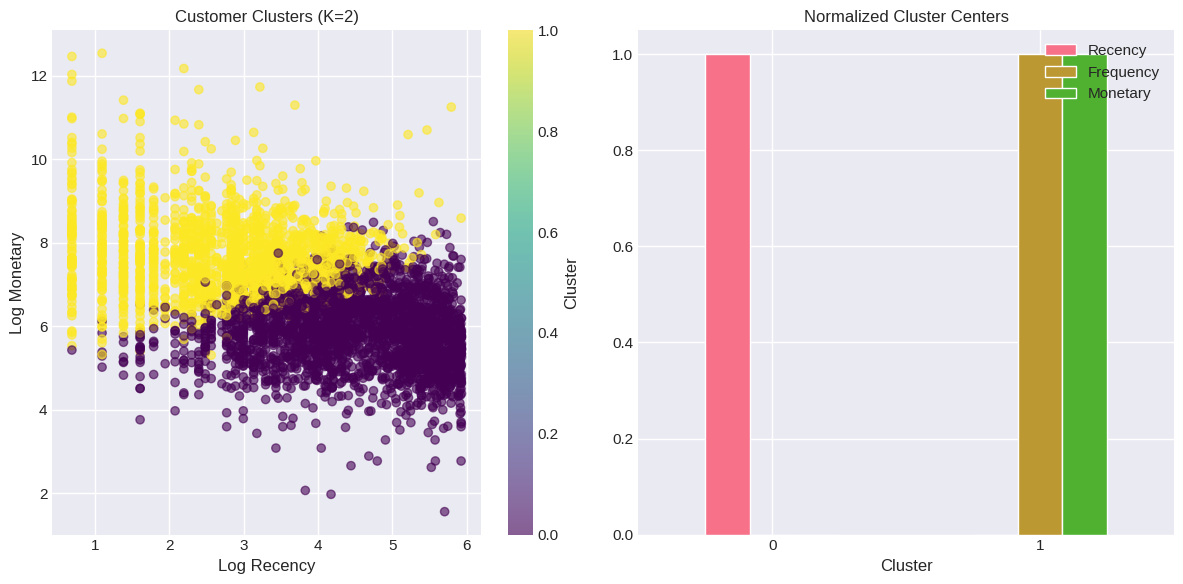


✓ Clustering visualization created (saved to figures/)


In [ ]:
print("\n" + "="*80)
print("SECTION 5: CUSTOMER SEGMENTATION (CLUSTERING)")
print("="*80)

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]
rfm_log = np.log1p(rfm_features)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Determining Optimal K...")
silhouette_scores = []
K_range = range(2, 6)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}, Silhouette={score:.4f}")

optimal_k = K_range[np.argmax(silhouette_scores)]
print(f"\nOptimal K based on Silhouette: {optimal_k}")

comparison_k = 2
print(f"\n--- Clustering Model Comparison (K={comparison_k}) ---")

models = {
    'K-Means': KMeans(n_clusters=comparison_k, random_state=42, n_init=10),
    'Hierarchical': AgglomerativeClustering(n_clusters=comparison_k),
    'Gaussian Mixture': GaussianMixture(n_components=comparison_k, random_state=42)
}

for name, model in models.items():
    labels = model.fit_predict(rfm_scaled)
    sil = silhouette_score(rfm_scaled, labels)
    db = davies_bouldin_score(rfm_scaled, labels)
    print(f"{name}: Silhouette={sil:.4f}, Davies-Bouldin={db:.4f}")

kmeans_final = KMeans(n_clusters=comparison_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# Visualization
plt.figure(figsize=(12, 6))

# 2D view: Recency vs Monetary
plt.subplot(1, 2, 1)
scatter = plt.scatter(
    rfm_log['Recency'],
    rfm_log['Monetary'],
    c=rfm['Cluster'],
    cmap='viridis',
    alpha=0.6
)
plt.xlabel('Log Recency')
plt.ylabel('Log Monetary')
plt.title(f'Customer Clusters (K={comparison_k})')
plt.colorbar(scatter, label='Cluster')

# Normalized cluster centers
plt.subplot(1, 2, 2)
cluster_avg = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
cluster_avg_norm = (cluster_avg - cluster_avg.min()) / (cluster_avg.max() - cluster_avg.min())
cluster_avg_norm.plot(kind='bar', ax=plt.gca())
plt.title('Normalized Cluster Centers')
plt.xlabel('Cluster')
plt.xticks(rotation=0)
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig('figures/clustering_results.png', dpi=300)
plt.show()

print("\n✓ Clustering visualization created (saved to figures/)")

fig = px.scatter_3d(
    rfm_log,
    x='Recency',
    y='Frequency',
    z='Monetary',
    color=rfm['Cluster'],
    title='3D Customer Clusters (RFM Space)'
)
fig.write_html("figures/clusters_3d.html")
fig.show()

print("✓ 3D cluster visualization created")



In [ ]:
'''6. Predictive Modeling – Churn / Retention Prediction

We use a **time-based split**:
- Train on all behavior before a cutoff (~90 days before the last date)
- Predict whether a customer will **return in the next 3 months**

Models compared:
- Logistic Regression
- Decision Tree
- Random Forest
'''

'6. Predictive Modeling – Churn / Retention Prediction\n\nWe use a **time-based split**:\n- Train on all behavior before a cutoff (~90 days before the last date)\n- Predict whether a customer will **return in the next 3 months**\n\nModels compared:\n- Logistic Regression  \n- Decision Tree  \n- Random Forest  \n'

In [ ]:
print("\n" + "="*80)
print("SECTION 6: PREDICTIVE MODELING - CHURN PREDICTION (CORRECTED)")
print("Methodology: Time-Series Split (Holdout Method)")
print("="*80)

# 1. Define Cutoff
max_date = df_sales['InvoiceDate'].max()
cutoff_date = max_date - pd.Timedelta(days=90)
print(f"Cutoff Date: {cutoff_date}")

# 2. Split Data
train_data = df_sales[df_sales['InvoiceDate'] < cutoff_date].copy()
test_data = df_sales[df_sales['InvoiceDate'] >= cutoff_date].copy()

# 3. Feature Engineering
X = train_data.groupby('CustomerID').agg({
    'TotalAmount': 'sum',
    'InvoiceNo': 'nunique',
    'Quantity': 'sum',
    'InvoiceDate': 'max'
}).reset_index()

X.columns = ['CustomerID', 'TotalSpent', 'Frequency', 'TotalQuantity', 'LastPurchaseDate']

first_purchase = train_data.groupby('CustomerID')['InvoiceDate'].min().reset_index()
first_purchase.columns = ['CustomerID', 'FirstPurchaseDate']
X = X.merge(first_purchase, on='CustomerID')

X['DaysSinceFirst'] = (cutoff_date - X['FirstPurchaseDate']).dt.days
X['Recency'] = (cutoff_date - X['LastPurchaseDate']).dt.days
X['AvgOrderValue'] = X['TotalSpent'] / X['Frequency']

# 4. Target Variable
future_customers = test_data['CustomerID'].unique()
X['WillReturn'] = X['CustomerID'].isin(future_customers).astype(int)

# 5. Prepare Data
feature_cols = ['TotalSpent', 'AvgOrderValue', 'TotalQuantity', 'DaysSinceFirst', 'Recency', 'Frequency']
X_model = X[feature_cols].fillna(0)
y_model = X['WillReturn']

scaler_pred = StandardScaler()
X_scaled = scaler_pred.fit_transform(X_model)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_model, test_size=0.25, random_state=42, stratify=y_model
)

# 6. Models
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

print("\n--- Model Performance (with Cross-Validation) ---")
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print(f"\n{name}:")
    print(f"  CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test ROC-AUC: {auc:.4f}")

# 7. Classification Report & Feature Importance (Random Forest)
best_model = models['Random Forest']
y_pred_rf = best_model.predict(X_test)

print("\n--- Classification Report (Random Forest) ---")
print(classification_report(y_test, y_pred_rf, target_names=['Churned', 'Retained']))

importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n--- Feature Importance ---")
print(importances)

print("\n" + "="*80)
print("ANALYSIS COMPLETE - OUTPUTS GENERATED")
print("="*80)


SECTION 6: PREDICTIVE MODELING - CHURN PREDICTION (CORRECTED)
Methodology: Time-Series Split (Holdout Method)
Cutoff Date: 2011-09-10 12:50:00

--- Model Performance (with Cross-Validation) ---

Logistic Regression:
  CV ROC-AUC: 0.7377 (+/- 0.0179)
  Test Accuracy: 0.6702
  Test ROC-AUC: 0.7221

Decision Tree:
  CV ROC-AUC: 0.7256 (+/- 0.0313)
  Test Accuracy: 0.6536
  Test ROC-AUC: 0.7109

Random Forest:
  CV ROC-AUC: 0.7243 (+/- 0.0174)
  Test Accuracy: 0.6572
  Test ROC-AUC: 0.7219

--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

     Churned       0.60      0.59      0.59       362
    Retained       0.70      0.71      0.70       481

    accuracy                           0.66       843
   macro avg       0.65      0.65      0.65       843
weighted avg       0.66      0.66      0.66       843


--- Feature Importance ---
          Feature  Importance
0      TotalSpent    0.216892
2   TotalQuantity    0.189647
4         Recenc

## Appended visualization cells copied from your notebook (DSE_501_Project_with_descrtions (2).ipynb)
Run these after the friend's cells. These cells are copied from your notebook and may reference variables present in the notebook state.

In [ ]:
# --- Appended plot cell 1 from your notebook ---
try:
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns

  # Set visualization style
  sns.set(style="whitegrid")

  # 1. Load the dataset
  # Ensure 'Online Retail.xlsx' is in the same folder as your notebook
  print("Loading data...")
  try:
      df = pd.read_excel('Online Retail.xlsx')
      print("Data loaded successfully.")
  except FileNotFoundError:
      print("Error: File not found. Please check the filename.")

  # 2. Initial Inspection
  print(f"Initial shape: {df.shape}")
  print(df.info())
except Exception as e:
      print("Appended plot cell 1 failed with:", e)


Loading data...
Data loaded successfully.
Initial shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


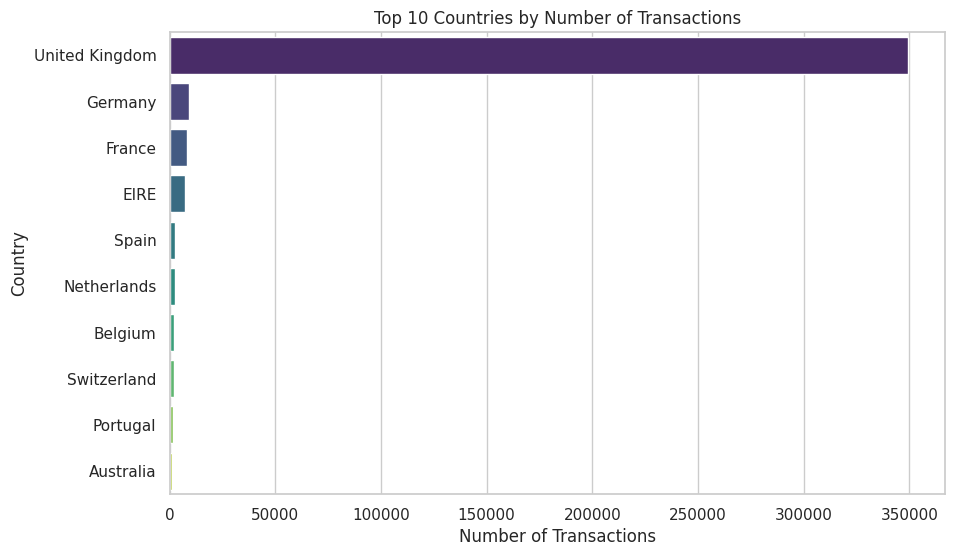

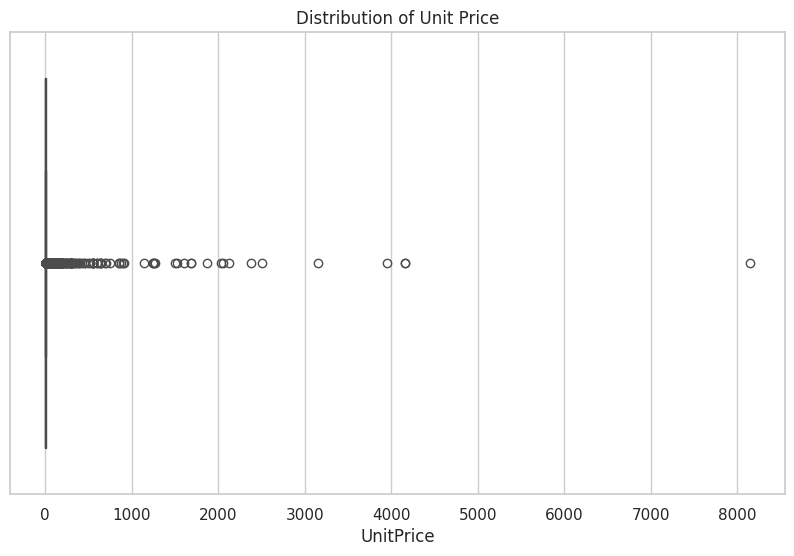

In [ ]:
# --- Appended plot cell 2 from your notebook ---
try:
  # --- EXPLORATORY DATA ANALYSIS ---

  # 1. Top 10 Countries by Number of Transactions
  top_countries = df_sales['Country'].value_counts().head(10)

  plt.figure(figsize=(10, 6))
  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
  plt.title('Top 10 Countries by Number of Transactions')
  plt.xlabel('Number of Transactions')
  plt.ylabel('Country')
  plt.show()

  # 2. Distribution of Unit Price (Checking for outliers)
  plt.figure(figsize=(10, 6))
  sns.boxplot(x=df_sales['UnitPrice'])
  plt.title('Distribution of Unit Price')
  plt.show()
except Exception as e:
    print("Appended plot cell 2 failed with:", e)


In [ ]:
# --- Appended plot cell 3 from your notebook ---
try:
  #Calculates RFM
  import datetime as dt

  # 1. Set a reference date for analysis
  # We typically use the day after the last transaction in the dataset
  latest_date = df_sales['InvoiceDate'].max() + dt.timedelta(days=1)
  print(f"Reference Date: {latest_date}")

  # 2. Group by CustomerID and calculate metrics
  rfm = df_sales.groupby('CustomerID').agg({
      'InvoiceDate': lambda x: (latest_date - x.max()).days, # Recency
      'InvoiceNo': 'nunique',                                # Frequency
      'TotalAmount': 'sum'                                   # Monetary
  })

  # 3. Rename columns for clarity
  rfm.rename(columns={
      'InvoiceDate': 'Recency',
      'InvoiceNo': 'Frequency',
      'TotalAmount': 'Monetary'
  }, inplace=True)

  # Initial check
  print(rfm.head())
  print(rfm.describe())
except Exception as e:
    print("Appended plot cell 3 failed with:", e)


Reference Date: 2011-12-10 12:50:00
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [ ]:
# --- Appended plot cell 4 from your notebook ---
try:
  # Assign scores
  # 1. Create labels for Recency (4 is best, 1 is worst - reverse order because low recency is good)
  r_labels = range(4, 0, -1)
  # Create labels for Frequency and Monetary (1 is worst, 4 is best)
  f_labels = range(1, 5)
  m_labels = range(1, 5)

  # 2. Assign quartiles using qcut
  rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels)

  # NOTE: For Frequency, we might have many customers with just 1 purchase, leading to duplicate bin edges.
  # We use .rank(method='first') to break ties if qcut fails directly.
  rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels)

  rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=m_labels)

  # 3. Combine scores into a single RFM Segment string
  rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

  # 4. Calculate a total "RFM Score" (Sum of individual scores)
  rfm['RFM_Sum'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

  display(rfm.head())
except Exception as e:
    print("Appended plot cell 4 failed with:", e)


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,RFM_Sum
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,4,114,6
12347.0,2,7,4310.00,4,4,4,444,12
12348.0,75,4,1797.24,2,3,4,234,9
12349.0,19,1,1757.55,3,1,4,314,8
12350.0,310,1,334.40,1,1,2,112,4


In [ ]:
# --- Appended plot cell 5 from your notebook ---
try:
  # Labelling the Segments
  # Define a function to map segments based on RFM_Sum
  def segment_customer(df):
      if df['RFM_Sum'] >= 9:
          return 'Champions'       # High value, frequent, recent
      elif df['RFM_Sum'] >= 8:
          return 'Loyal Customers' # Good frequency and value
      elif df['RFM_Sum'] >= 6:
          return 'Potential Loyalists'
      elif df['RFM_Sum'] >= 5:
          return 'At Risk'         # Haven't bought in a while
      else:
          return 'Hibernating/Lost'

  # Apply the function
  rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

  # View the distribution of segments
  segment_counts = rfm['Customer_Segment'].value_counts()
  print(segment_counts)
except Exception as e:
    print("Appended plot cell 5 failed with:", e)


Customer_Segment
Champions              1677
Potential Loyalists     935
Hibernating/Lost        806
At Risk                 485
Loyal Customers         435
Name: count, dtype: int64


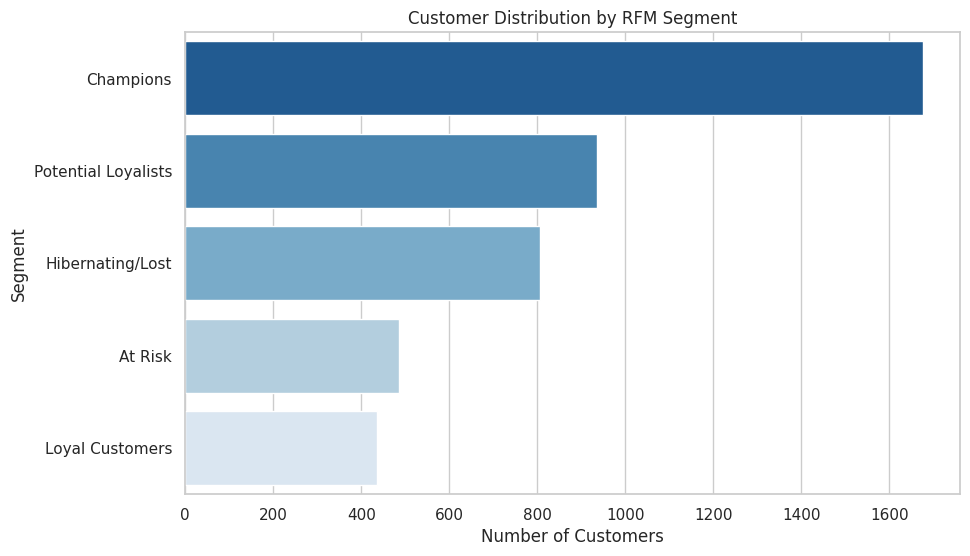

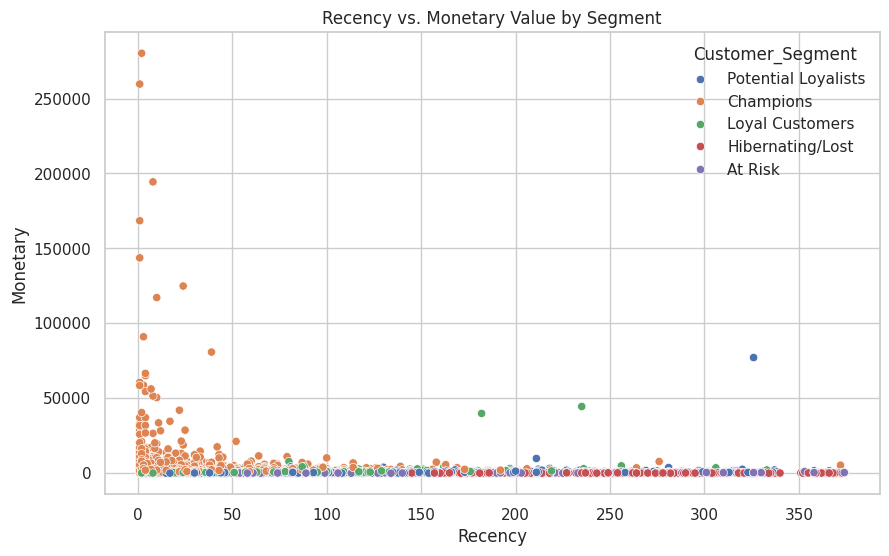

In [ ]:
# --- Appended plot cell 6 from your notebook ---
try:
  # Visualizing the Segments
  plt.figure(figsize=(10, 6))
  sns.barplot(x=segment_counts.values, y=segment_counts.index, palette='Blues_r')
  plt.title('Customer Distribution by RFM Segment')
  plt.xlabel('Number of Customers')
  plt.ylabel('Segment')
  plt.show()

  # Scatter plot: Recency vs. Monetary (Color by Segment)
  plt.figure(figsize=(10, 6))
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Customer_Segment', palette='deep')
  plt.title('Recency vs. Monetary Value by Segment')
  plt.show()
except Exception as e:
    print("Appended plot cell 6 failed with:", e)


--- 1. Transaction Level Diagnostics (Quantity & Price) ---


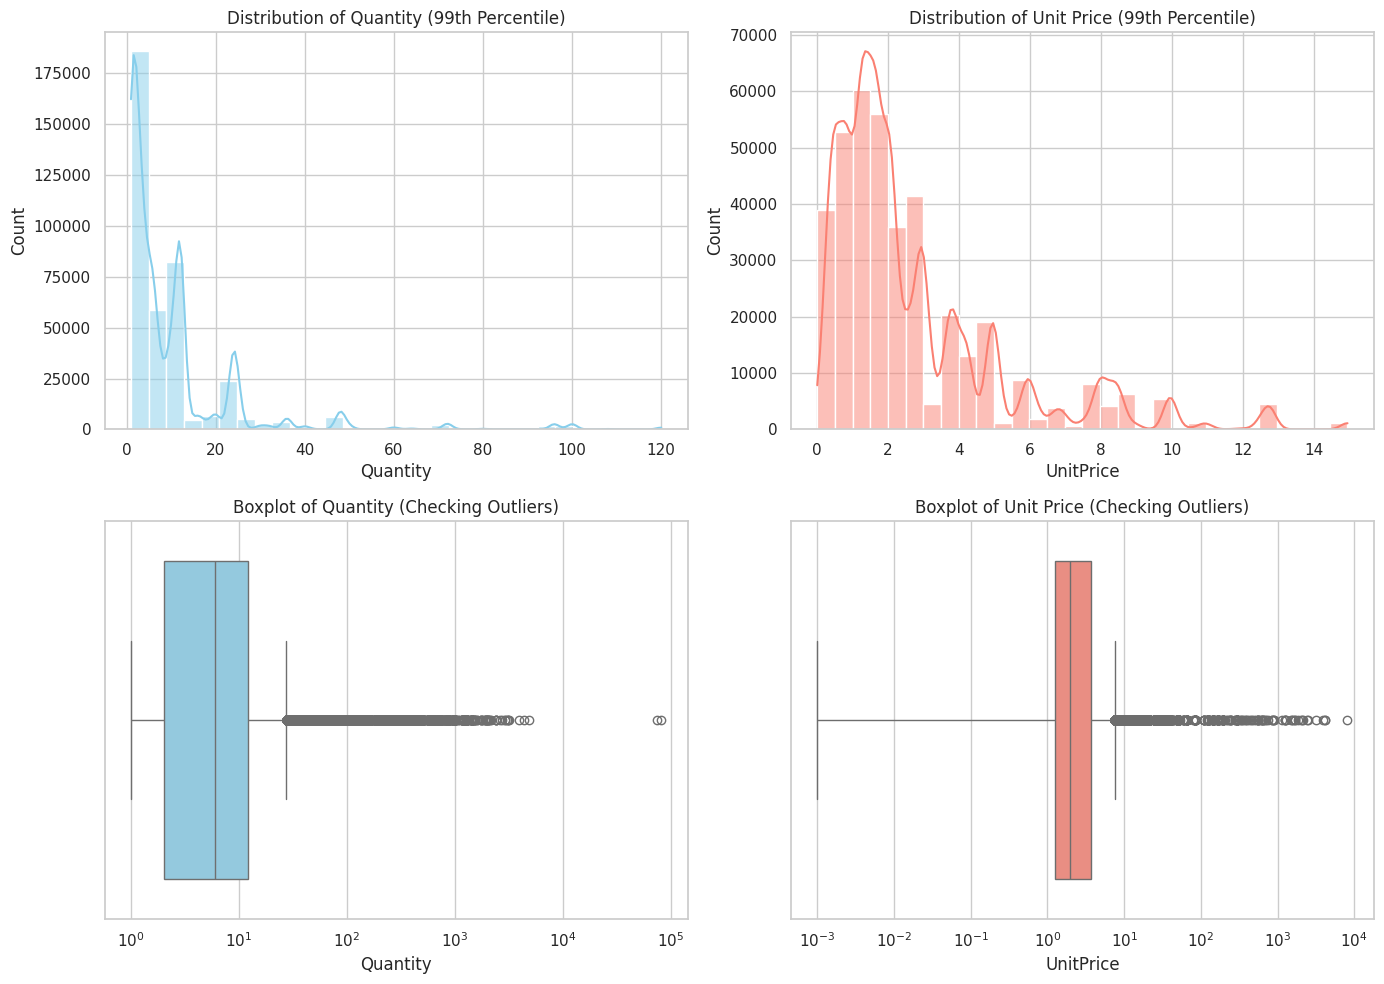


--- 2. Customer Level Diagnostics (RFM Metrics) ---


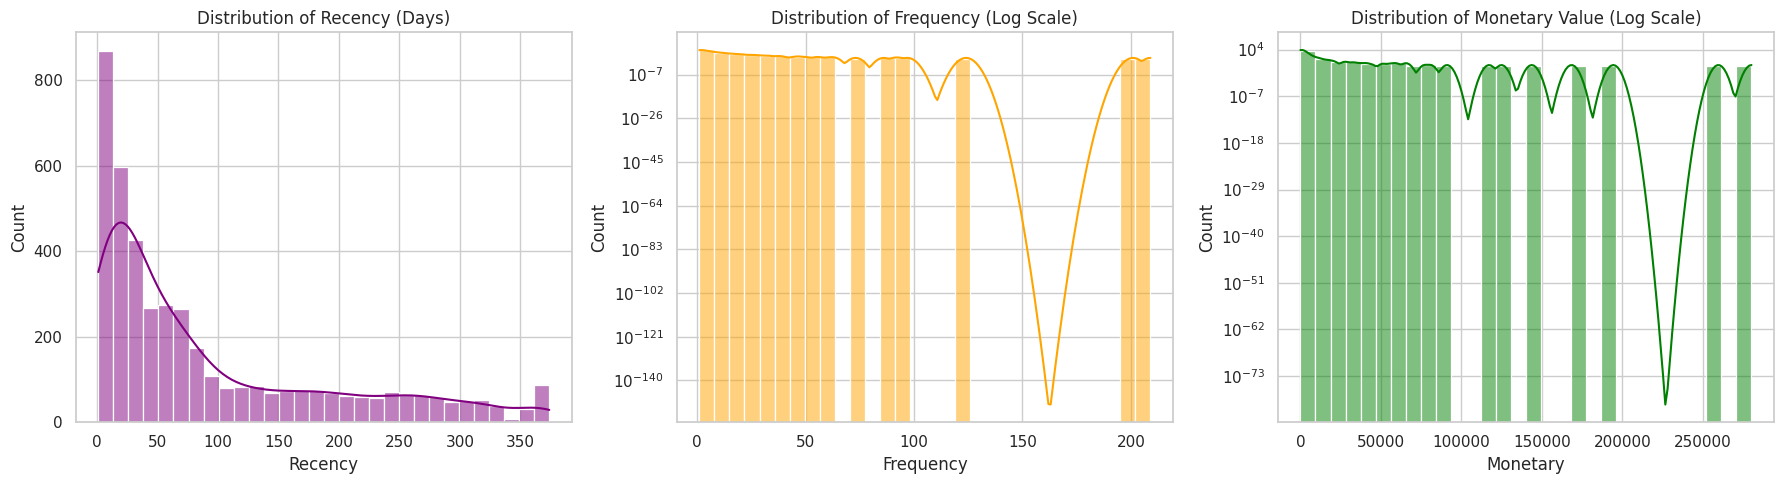


--- 3. Correlation Matrix (RFM) ---


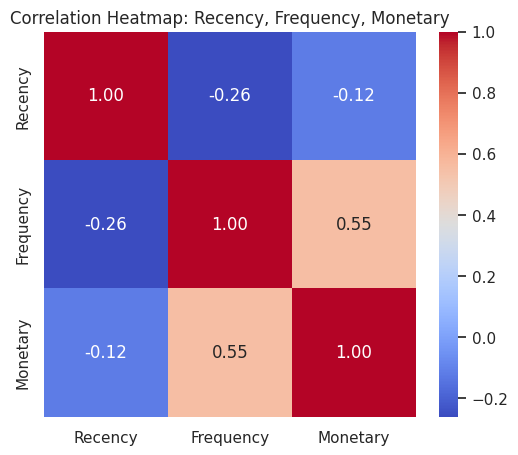

In [ ]:
# --- Appended plot cell 7 from your notebook ---
try:
  # ==========================================
  # DATA DIAGNOSTICS & DISTRIBUTIONS
  # ==========================================
  import matplotlib.pyplot as plt
  import seaborn as sns
  import numpy as np

  # Set the style
  sns.set(style="whitegrid")

  # --- 1. TRANSACTION LEVEL DIAGNOSTICS (df_sales) ---
  print("--- 1. Transaction Level Diagnostics (Quantity & Price) ---")
  fig, axes = plt.subplots(2, 2, figsize=(14, 10))

  # Quantity Distribution (Clipped for visibility)
  # We limit the x-axis to the 99th percentile to hide extreme bulk-buy outliers for the plot
  q_99 = df_sales['Quantity'].quantile(0.99)
  sns.histplot(df_sales[df_sales['Quantity'] <= q_99]['Quantity'], bins=30, kde=True, ax=axes[0,0], color='skyblue')
  axes[0,0].set_title('Distribution of Quantity (99th Percentile)')

  # UnitPrice Distribution (Clipped for visibility)
  p_99 = df_sales['UnitPrice'].quantile(0.99)
  sns.histplot(df_sales[df_sales['UnitPrice'] <= p_99]['UnitPrice'], bins=30, kde=True, ax=axes[0,1], color='salmon')
  axes[0,1].set_title('Distribution of Unit Price (99th Percentile)')

  # Boxplot for Quantity
  sns.boxplot(x=df_sales['Quantity'], ax=axes[1,0], color='skyblue')
  axes[1,0].set_title('Boxplot of Quantity (Checking Outliers)')
  axes[1,0].set_xscale('log') # Log scale helps visualize extreme outliers

  # Boxplot for UnitPrice
  sns.boxplot(x=df_sales['UnitPrice'], ax=axes[1,1], color='salmon')
  axes[1,1].set_title('Boxplot of Unit Price (Checking Outliers)')
  axes[1,1].set_xscale('log')

  plt.tight_layout()
  plt.show()


  # --- 2. CUSTOMER LEVEL DIAGNOSTICS (RFM Table) ---
  print("\n--- 2. Customer Level Diagnostics (RFM Metrics) ---")
  fig, axes = plt.subplots(1, 3, figsize=(18, 5))

  # Recency Distribution
  sns.histplot(rfm['Recency'], bins=30, kde=True, ax=axes[0], color='purple')
  axes[0].set_title('Distribution of Recency (Days)')

  # Frequency Distribution (Log scale due to "Super Buyers")
  sns.histplot(rfm['Frequency'], bins=30, kde=True, ax=axes[1], color='orange')
  axes[1].set_title('Distribution of Frequency (Log Scale)')
  axes[1].set_yscale('log')

  # Monetary Distribution (Log scale due to "Whales")
  sns.histplot(rfm['Monetary'], bins=30, kde=True, ax=axes[2], color='green')
  axes[2].set_title('Distribution of Monetary Value (Log Scale)')
  axes[2].set_yscale('log')

  plt.tight_layout()
  plt.show()

  # --- 3. CORRELATION MATRIX ---
  # Checking how R, F, and M relate to each other
  print("\n--- 3. Correlation Matrix (RFM) ---")
  plt.figure(figsize=(6, 5))
  correlation = rfm[['Recency', 'Frequency', 'Monetary']].corr()
  sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
  plt.title('Correlation Heatmap: Recency, Frequency, Monetary')
  plt.show()
except Exception as e:
    print("Appended plot cell 7 failed with:", e)



--- 3. Overall Business Diagnostics (Time & Product) ---


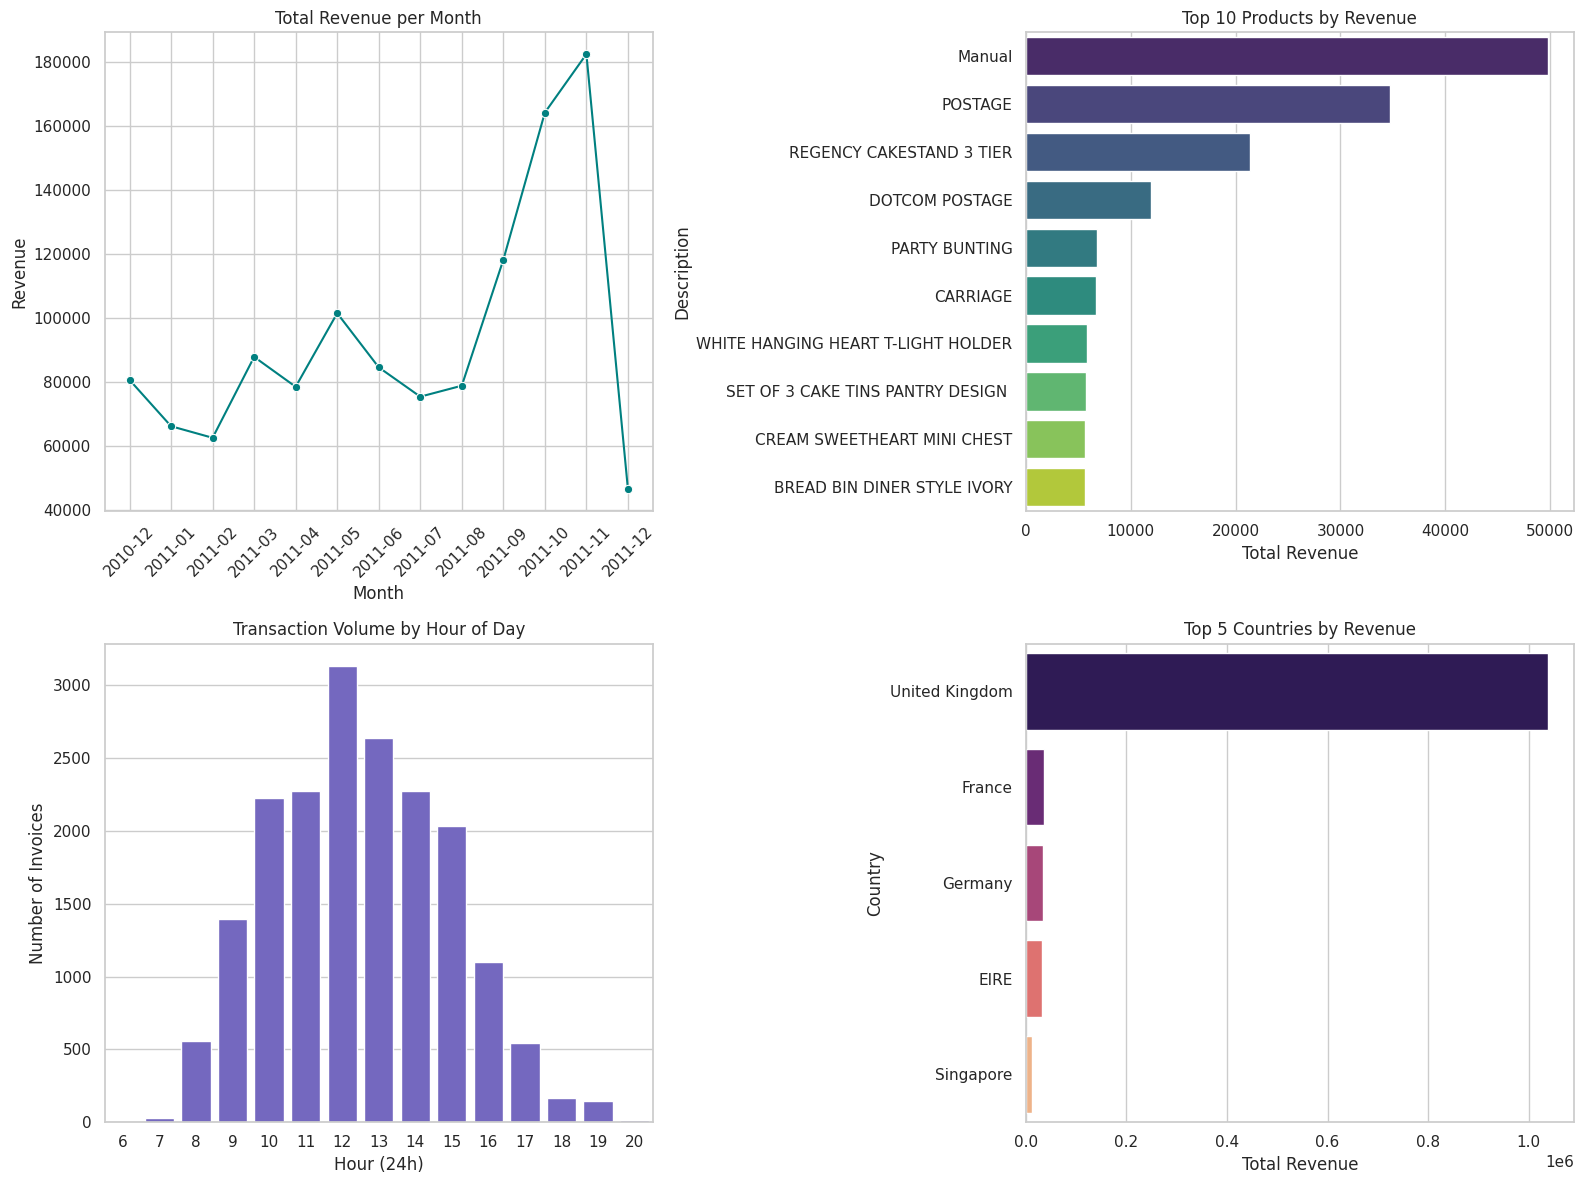

In [ ]:
# --- Appended plot cell 8 from your notebook ---
try:
  # ==========================================
  # 3. MACRO BUSINESS DIAGNOSTICS (Overall Trends)
  # ==========================================

  # Prepare data for time series (Group by Month)
  # Ensure InvoiceDate is datetime
  df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])
  df_sales['Month'] = df_sales['InvoiceDate'].dt.to_period('M')

  # Group by Month to get total sales
  monthly_sales = df_sales.groupby('Month')['UnitPrice'].sum()
  monthly_sales.index = monthly_sales.index.astype(str) # Convert to string for plotting

  print("\n--- 3. Overall Business Diagnostics (Time & Product) ---")
  fig, axes = plt.subplots(2, 2, figsize=(16, 12))

  # A. Monthly Sales Trend
  sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', ax=axes[0,0], color='teal')
  axes[0,0].set_title('Total Revenue per Month')
  axes[0,0].set_xticklabels(monthly_sales.index, rotation=45)
  axes[0,0].set_ylabel('Revenue')

  # B. Top 10 Selling Products (by Revenue)
  top_products = df_sales.groupby('Description')['UnitPrice'].sum().sort_values(ascending=False).head(10)
  sns.barplot(y=top_products.index, x=top_products.values, ax=axes[0,1], palette='viridis')
  axes[0,1].set_title('Top 10 Products by Revenue')
  axes[0,1].set_xlabel('Total Revenue')

  # C. Hourly Sales Trend (When do people buy?)
  df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour
  hourly_sales = df_sales.groupby('Hour')['InvoiceNo'].nunique() # Count unique invoices per hour
  sns.barplot(x=hourly_sales.index, y=hourly_sales.values, ax=axes[1,0], color='slateblue')
  axes[1,0].set_title('Transaction Volume by Hour of Day')
  axes[1,0].set_xlabel('Hour (24h)')
  axes[1,0].set_ylabel('Number of Invoices')

  # D. Sales by Country (Top 5 excluding UK if it dominates)
  # We check the top countries first
  top_countries = df_sales.groupby('Country')['UnitPrice'].sum().sort_values(ascending=False).head(5)
  sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1,1], palette='magma')
  axes[1,1].set_title('Top 5 Countries by Revenue')
  axes[1,1].set_xlabel('Total Revenue')

  plt.tight_layout()
  plt.show()
except Exception as e:
    print("Appended plot cell 8 failed with:", e)


--- H1 Results: Frequency vs Monetary ---
High Freq Mean: £5684.44 | Low Freq Mean: £411.25
T-statistic: 10.8273, P-value: 4.5169e-26
Significant? Yes


--- H2 Results: Loyalty vs AOV ---
Repeat Cust AOV: £421.00 | Single Cust AOV: £411.25
T-statistic: 0.1596, P-value: 8.7320e-01


--- H3 Results: Weekly Seasonality ---
F-statistic: 1.1826, P-value: 3.1481e-01


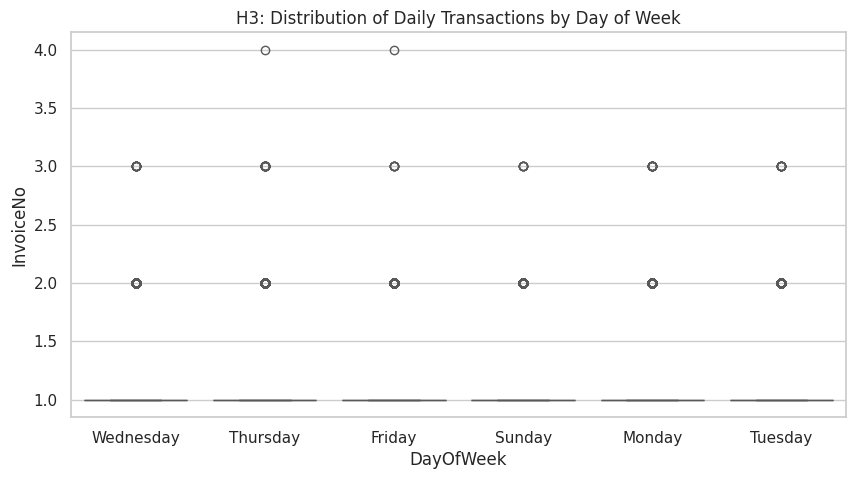



--- H4 Results: UK vs International AOV ---
Intl Mean: £849.51 | UK Mean: £437.64
T-statistic: 9.6829, P-value: 9.2862e-22


--- H5 Results: Cancellations by Country ---
Chi2 Statistic: 693.4009, P-value: 1.8134e-143
Contingency Table (Top 5 rows):


IsCancelled,0,1
Country,,
Australia,1185,74
Belgium,2031,38
EIRE,7894,302
France,8408,149
Germany,9042,453


In [ ]:
# --- Appended plot cell 9 from your notebook ---
try:
  import scipy.stats as stats
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns

  # Ensure you have the 'rfm' and 'df_sales' dataframes from the previous steps
  # We also need the original 'df' (with negative values) for H5

  # ==========================================
  # H1: Frequency-Monetary Relationship
  # ==========================================
  # H0: No significant difference in monetary value between high and low frequency customers [cite: 34]
  # H1: High-frequency customers have higher monetary value [cite: 35]

  # 1. Define Quartiles based on Frequency
  # Top 25% (High Frequency) vs Bottom 25% (Low Frequency)
  q75 = rfm['Frequency'].quantile(0.75)
  q25 = rfm['Frequency'].quantile(0.25)

  high_freq_group = rfm[rfm['Frequency'] >= q75]['Monetary']
  low_freq_group = rfm[rfm['Frequency'] <= q25]['Monetary']

  # 2. Perform Independent Samples t-test
  t_stat_h1, p_val_h1 = stats.ttest_ind(high_freq_group, low_freq_group, equal_var=False) # Welch's t-test

  print(f"--- H1 Results: Frequency vs Monetary ---")
  print(f"High Freq Mean: £{high_freq_group.mean():.2f} | Low Freq Mean: £{low_freq_group.mean():.2f}")
  print(f"T-statistic: {t_stat_h1:.4f}, P-value: {p_val_h1:.4e}")
  print("Significant?" , "Yes" if p_val_h1 < 0.05 else "No")
  print("\n")


  # ==========================================
  # H2: Customer Loyalty and Order Value
  # ==========================================
  # H0: No difference in Average Order Value (AOV) between single vs repeat customers [cite: 39]

  # 1. Calculate Average Order Value (AOV) per customer
  rfm['AOV'] = rfm['Monetary'] / rfm['Frequency']

  # 2. Split Groups
  single_purchase = rfm[rfm['Frequency'] == 1]['AOV']
  repeat_customers = rfm[rfm['Frequency'] > 1]['AOV']

  # 3. Perform t-test
  t_stat_h2, p_val_h2 = stats.ttest_ind(repeat_customers, single_purchase, equal_var=False)

  print(f"--- H2 Results: Loyalty vs AOV ---")
  print(f"Repeat Cust AOV: £{repeat_customers.mean():.2f} | Single Cust AOV: £{single_purchase.mean():.2f}")
  print(f"T-statistic: {t_stat_h2:.4f}, P-value: {p_val_h2:.4e}")
  print("\n")


  # ==========================================
  # H3: Weekly Transaction Pattern
  # ==========================================
  # H0: Mean transactions are equal across days of the week [cite: 46]
  # Test: One-way ANOVA [cite: 47]

  # 1. Aggregate transactions by Date and DayOfWeek
  # We need the count of unique InvoiceNos per day
  daily_transactions = df_sales.groupby(['InvoiceDate', 'DayOfWeek'])['InvoiceNo'].nunique().reset_index()

  # 2. Prepare groups for ANOVA
  groups_h3 = [daily_transactions[daily_transactions['DayOfWeek'] == day]['InvoiceNo']
              for day in daily_transactions['DayOfWeek'].unique()]

  # 3. Perform One-way ANOVA
  f_stat_h3, p_val_h3 = stats.f_oneway(*groups_h3)

  print(f"--- H3 Results: Weekly Seasonality ---")
  print(f"F-statistic: {f_stat_h3:.4f}, P-value: {p_val_h3:.4e}")
  # Optional: Boxplot to visualize
  plt.figure(figsize=(10,5))
  sns.boxplot(x='DayOfWeek', y='InvoiceNo', data=daily_transactions, palette='Set2')
  plt.title("H3: Distribution of Daily Transactions by Day of Week")
  plt.show()
  print("\n")


  # ==========================================
  # H4: Domestic vs. International Order Value
  # ==========================================
  # H0: No difference in order value between UK and International [cite: 53]

  # 1. Calculate Order Value for every specific Invoice
  invoice_values = df_sales.groupby(['InvoiceNo', 'Country'])['TotalAmount'].sum().reset_index()

  # 2. Split Groups
  uk_orders = invoice_values[invoice_values['Country'] == 'United Kingdom']['TotalAmount']
  intl_orders = invoice_values[invoice_values['Country'] != 'United Kingdom']['TotalAmount']

  # 3. Perform t-test
  t_stat_h4, p_val_h4 = stats.ttest_ind(intl_orders, uk_orders, equal_var=False)

  print(f"--- H4 Results: UK vs International AOV ---")
  print(f"Intl Mean: £{intl_orders.mean():.2f} | UK Mean: £{uk_orders.mean():.2f}")
  print(f"T-statistic: {t_stat_h4:.4f}, P-value: {p_val_h4:.4e}")
  print("\n")


  # ==========================================
  # H5: Geographic Variation in Cancellation Rates
  # ==========================================
  # H0: Proportion of cancelled transactions is equal across countries [cite: 58]
  # Test: Chi-square test [cite: 60]

  # 1. Use the original raw 'df' to identify cancellations (Negative Quantity)
  # Create a binary flag: 1 if Cancelled (Quantity < 0), else 0
  df_h5 = df.copy() # Assuming 'df' is your raw loaded dataframe
  df_h5['IsCancelled'] = np.where(df_h5['Quantity'] < 0, 1, 0)

  # 2. Create Contingency Table (Country vs IsCancelled)
  # We focus on the top 10 countries to ensure sufficient sample size for Chi-Square
  top_countries_list = df_h5['Country'].value_counts().head(10).index
  df_h5_top = df_h5[df_h5['Country'].isin(top_countries_list)]

  contingency_table = pd.crosstab(df_h5_top['Country'], df_h5_top['IsCancelled'])

  # 3. Perform Chi-Square Test
  chi2, p_val_h5, dof, expected = stats.chi2_contingency(contingency_table)

  print(f"--- H5 Results: Cancellations by Country ---")
  print(f"Chi2 Statistic: {chi2:.4f}, P-value: {p_val_h5:.4e}")
  print("Contingency Table (Top 5 rows):")
  display(contingency_table.head())
except Exception as e:
    print("Appended plot cell 9 failed with:", e)


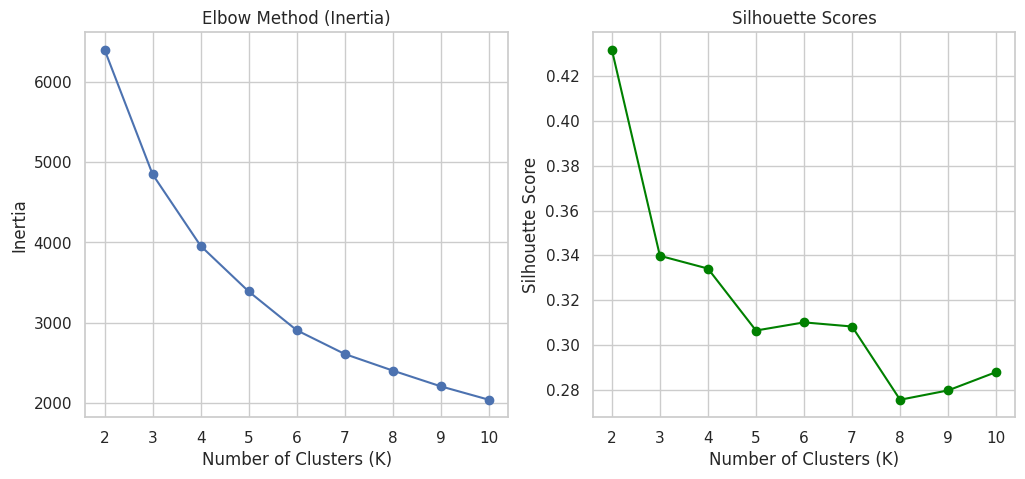

Cluster Centers (Mean Values):


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,13.250960,13.033291,7608.193726
1,161.329216,1.275510,339.490570
2,53.497935,3.526844,1364.647878


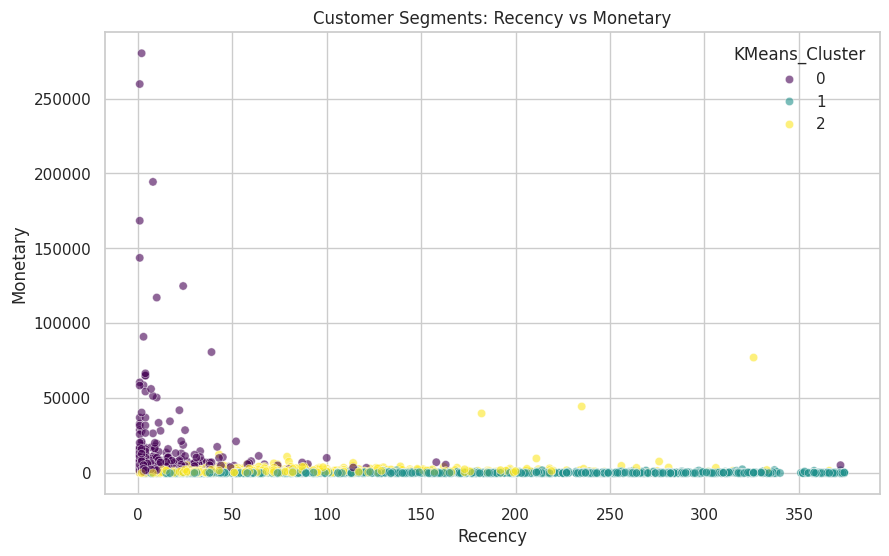

In [ ]:
# --- Appended plot cell 10 from your notebook ---
try:
  from sklearn.preprocessing import StandardScaler
  from sklearn.cluster import KMeans
  from sklearn.metrics import silhouette_score

  # --- STEP 1: PREPROCESSING ---
  # RFM distributions are usually right-skewed. Log transformation fixes this.
  rfm_log = np.log(rfm[['Recency', 'Frequency', 'Monetary']])

  # Scale the data (K-Means requires variables on the same scale)
  scaler = StandardScaler()
  rfm_scaled = scaler.fit_transform(rfm_log)

  # --- STEP 2: COMPARE MODELS (ELBOW METHOD) ---
  # We test cluster counts (K) from 2 to 10 to find the best fit
  inertia = []
  silhouette_scores = []
  k_range = range(2, 11)

  for k in k_range:
      kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
      kmeans.fit(rfm_scaled)
      inertia.append(kmeans.inertia_)
      silhouette_scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

  # Plot 1: The Elbow Curve (To find optimal K)
  plt.figure(figsize=(12, 5))
  plt.subplot(1, 2, 1)
  plt.plot(k_range, inertia, marker='o')
  plt.title('Elbow Method (Inertia)')
  plt.xlabel('Number of Clusters (K)')
  plt.ylabel('Inertia')

  # Plot 2: Silhouette Scores (Higher is better)
  plt.subplot(1, 2, 2)
  plt.plot(k_range, silhouette_scores, marker='o', color='green')
  plt.title('Silhouette Scores')
  plt.xlabel('Number of Clusters (K)')
  plt.ylabel('Silhouette Score')
  plt.show()

  # --- STEP 3: FINAL MODEL BUILDING (Assuming K=3 or K=4 based on plots) ---
  # Let's assume K=3 is chosen based on the Elbow (you can change this after seeing the plot)
  best_k = 3
  final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
  final_labels = final_model.fit_predict(rfm_scaled)

  # Assign clusters back to original RFM data
  rfm['KMeans_Cluster'] = final_labels

  # --- STEP 4: INTERPRETATION ---
  # Analyze the mean RFM values for each cluster
  cluster_summary = rfm.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
  print("Cluster Centers (Mean Values):")
  display(cluster_summary)

  # Visualize Clusters
  plt.figure(figsize=(10, 6))
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='KMeans_Cluster', palette='viridis', alpha=0.6)
  plt.title('Customer Segments: Recency vs Monetary')
  plt.show()
except Exception as e:
    print("Appended plot cell 10 failed with:", e)


In [ ]:
# --- Appended plot cell 11 from your notebook ---
try:
  import matplotlib.pyplot as plt
  import seaborn as sns

  # Add labels to the original RFM dataframe to visualize
  rfm['KMeans_Labels'] = kmeans_labels
  rfm['Agglo_Labels'] = agglo_labels
  rfm['GMM_Labels'] = gmm_labels

  # Plotting
  fig, axes = plt.subplots(1, 3, figsize=(20, 6))

  # Plot 1: K-Means
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='KMeans_Labels', palette='viridis', ax=axes[0])
  axes[0].set_title(f'K-Means Clustering (K={K})')

  # Plot 2: Hierarchical
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Agglo_Labels', palette='viridis', ax=axes[1])
  axes[1].set_title(f'Hierarchical Clustering (K={K})')

  # Plot 3: GMM
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='GMM_Labels', palette='viridis', ax=axes[2])
  axes[2].set_title(f'Gaussian Mixture (K={K})')

  plt.tight_layout()
  plt.show()
except Exception as e:
    print("Appended plot cell 11 failed with:", e)


Appended plot cell 11 failed with: name 'kmeans_labels' is not defined


--- 1. Performing Time-Series Analysis (Daily/Weekly Trend) ---


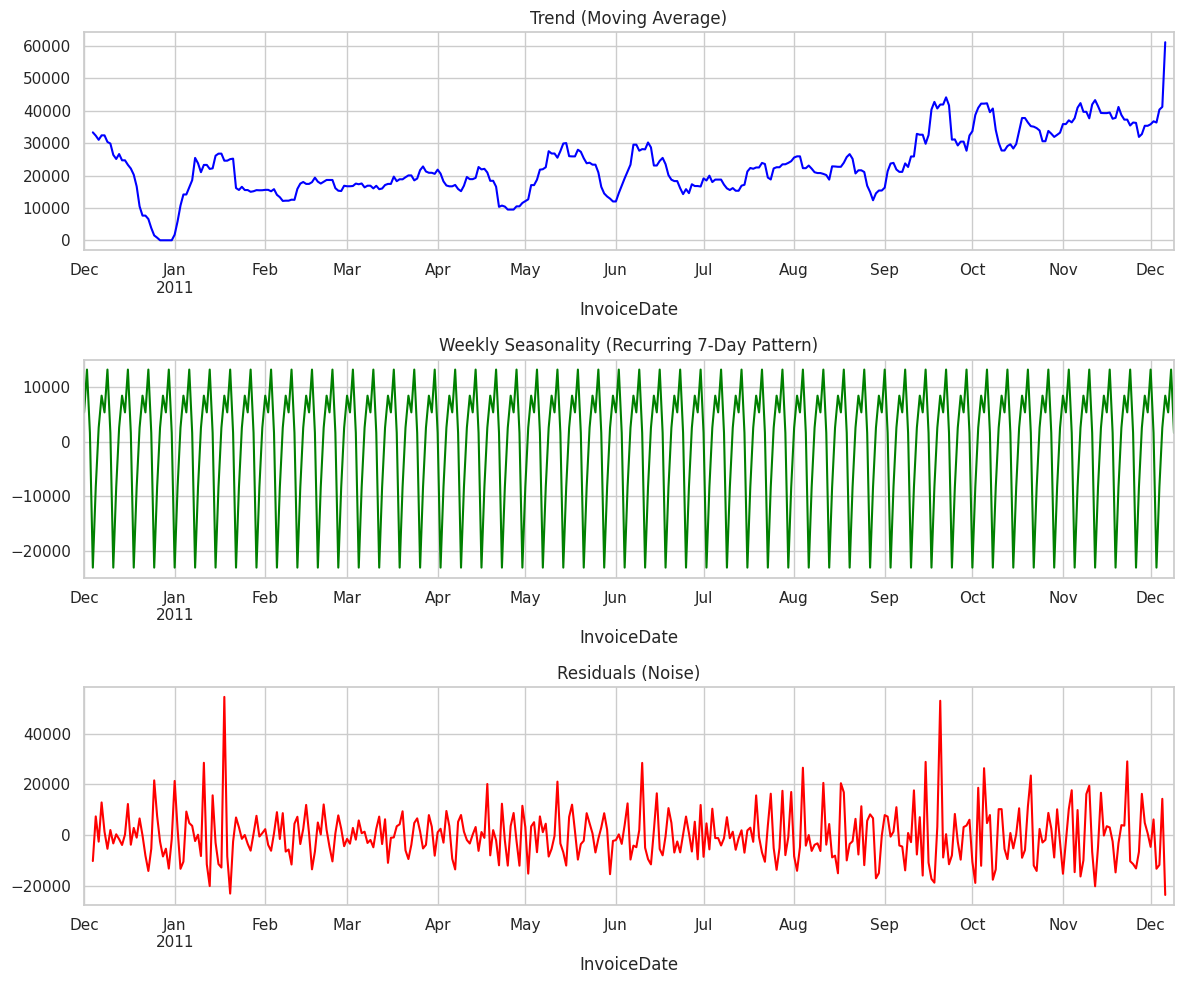

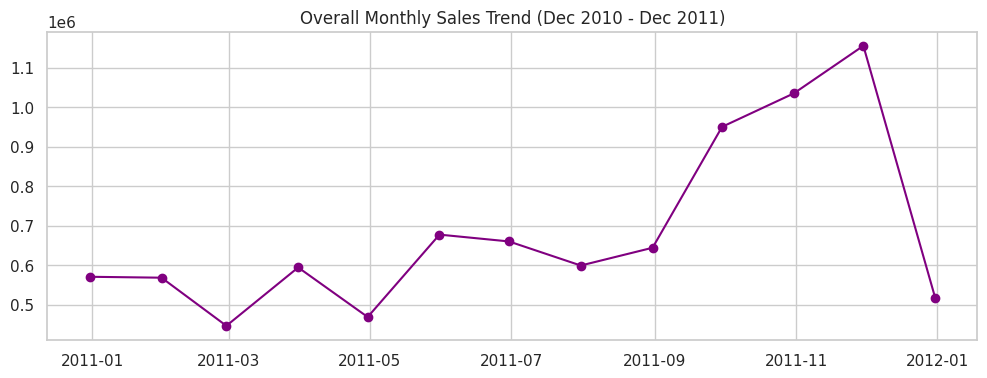


--- 2. Calculating Return Rates ---
Top 10 Products with Highest Return Rates:


,Total_Sold,Total_Returned,Return_Rate
Description,,,
check,1217,13247,0.915860
damaged,192,1824,0.904762
wrongly coded 20713,800,1000,0.555556
?,8112,9496,0.539300
"PAPER CRAFT , LITTLE BIRDIE",80995,80995,0.500000
incorrectly credited C550456 see 47,1300,1300,0.500000
ROTATING SILVER ANGELS T-LIGHT HLDR,9476,9376,0.497348
MEDIUM CERAMIC TOP STORAGE JAR,78033,74494,0.488399
SET OF 3 BABUSHKA STACKING TINS,275,255,0.481132



--- 3. Building Cohort Analysis ---


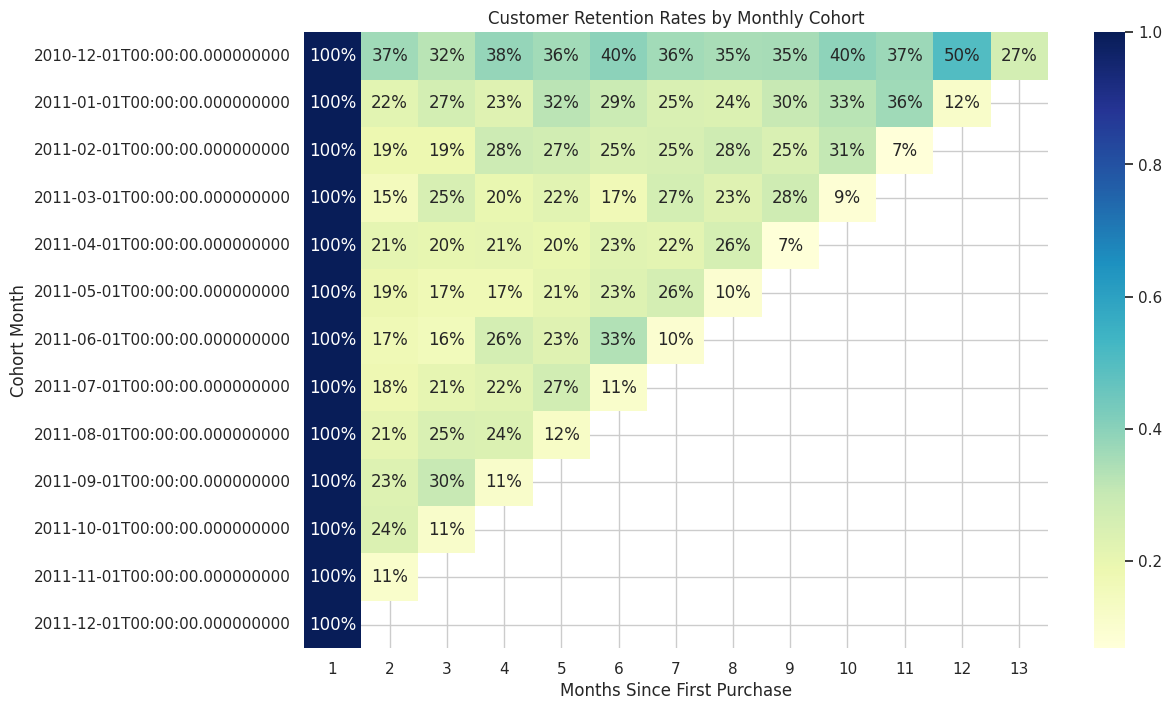

In [ ]:
# --- Appended plot cell 12 from your notebook ---
try:
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns
  import datetime as dt
  from statsmodels.tsa.seasonal import seasonal_decompose

  # ==========================================
  # PART 1: ADDITIONAL ANALYSES
  # ==========================================

  # --- SECTION A: TIME-SERIES DECOMPOSITION (Fixed) ---
  print("--- 1. Performing Time-Series Analysis (Daily/Weekly Trend) ---")

  # 1. Prepare Daily Sales Data
  # We use 'D' (Day) instead of 'M' (Month) to allow decomposition on 1 year of data
  # We also use 'ME' (Month End) for the simple trend line to avoid warnings
  daily_sales = df_sales.set_index('InvoiceDate').resample('D')['TotalAmount'].sum().fillna(0)

  # 2. Decompose (Period=7 detects Weekly patterns)
  decomposition = seasonal_decompose(daily_sales, model='additive', period=7)

  # 3. Plot Decomposition
  fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10))
  decomposition.trend.plot(ax=ax1, title='Trend (Moving Average)', color='blue')
  decomposition.seasonal.plot(ax=ax2, title='Weekly Seasonality (Recurring 7-Day Pattern)', color='green')
  decomposition.resid.plot(ax=ax3, title='Residuals (Noise)', color='red')
  plt.tight_layout()
  plt.show()

  # 4. Simple Monthly Trend Visualization
  monthly_trend = df_sales.set_index('InvoiceDate').resample('ME')['TotalAmount'].sum()
  plt.figure(figsize=(12, 4))
  plt.plot(monthly_trend.index, monthly_trend.values, marker='o', linestyle='-', color='purple')
  plt.title("Overall Monthly Sales Trend (Dec 2010 - Dec 2011)")
  plt.grid(True)
  plt.show()


  # --- SECTION B: RETURN RATE ANALYSIS ---
  print("\n--- 2. Calculating Return Rates ---")

  # 1. Aggregate by Product (using the raw 'df' to catch negative quantities)
  product_stats = df.groupby('Description').agg({
      'Quantity': [
          ('Total_Sold', lambda x: x[x > 0].sum()),
          ('Total_Returned', lambda x: abs(x[x < 0].sum()))
      ]
  })
  # Flatten columns
  product_stats.columns = product_stats.columns.droplevel()

  # 2. Calculate Return Rate %
  product_stats['Return_Rate'] = product_stats['Total_Returned'] / (product_stats['Total_Sold'] + product_stats['Total_Returned'])

  # 3. Filter and Display (Min 50 sold to be significant)
  high_return_products = product_stats[product_stats['Total_Sold'] > 50].sort_values('Return_Rate', ascending=False).head(10)
  print("Top 10 Products with Highest Return Rates:")
  display(high_return_products)


  # --- SECTION C: COHORT ANALYSIS (RETENTION) ---
  print("\n--- 3. Building Cohort Analysis ---")

  # 1. Create Cohort Variables
  df_cohort = df_sales.copy()
  # Function to get the first day of the month
  def get_month(x): return dt.datetime(x.year, x.month, 1)

  df_cohort['InvoiceMonth'] = df_cohort['InvoiceDate'].apply(get_month)
  # Assign Cohort Month (Month of First Purchase) to every transaction
  df_cohort['CohortMonth'] = df_cohort.groupby('CustomerID')['InvoiceMonth'].transform('min')

  # 2. Calculate Cohort Index (Months passed since first purchase)
  def get_date_int(df, column):
      year = df[column].dt.year
      month = df[column].dt.month
      return year, month

  invoice_year, invoice_month = get_date_int(df_cohort, 'InvoiceMonth')
  cohort_year, cohort_month = get_date_int(df_cohort, 'CohortMonth')

  years_diff = invoice_year - cohort_year
  months_diff = invoice_month - cohort_month

  df_cohort['CohortIndex'] = years_diff * 12 + months_diff + 1

  # 3. Pivot Data for Heatmap
  cohort_data = df_cohort.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()
  cohort_count = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

  # 4. Calculate Retention Rate
  cohort_size = cohort_count.iloc[:,0]
  retention = cohort_count.divide(cohort_size, axis=0)

  # 5. Plot Heatmap
  plt.figure(figsize=(12, 8))
  sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
  plt.title('Customer Retention Rates by Monthly Cohort')
  plt.ylabel('Cohort Month')
  plt.xlabel('Months Since First Purchase')
  plt.show()
except Exception as e:
    print("Appended plot cell 12 failed with:", e)


--- 4. Predictive Modeling: Will the Customer Return? ---

Feature dtypes (preview):
UnitPrice    float64
Quantity       int64
Month_sin    float64
Month_cos    float64
dtype: object

Dataset size: (4338, 4), Positive class ratio: 0.656

Classification Report:
              precision    recall  f1-score   support

           0     0.4653    0.4933    0.4789       448
           1     0.7255    0.7026    0.7139       854

    accuracy                         0.6306      1302
   macro avg     0.5954    0.5979    0.5964      1302
weighted avg     0.6360    0.6306    0.6330      1302

ROC-AUC Score: 0.6465


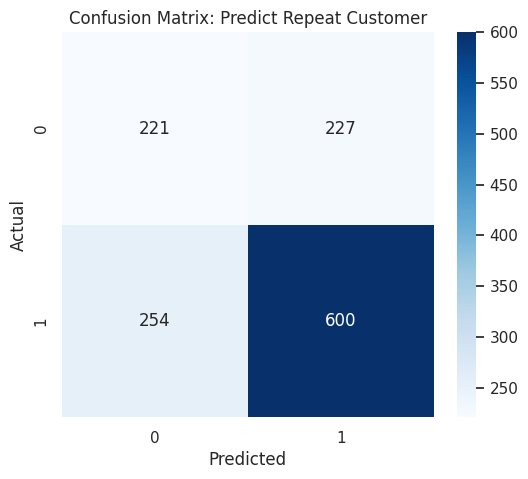

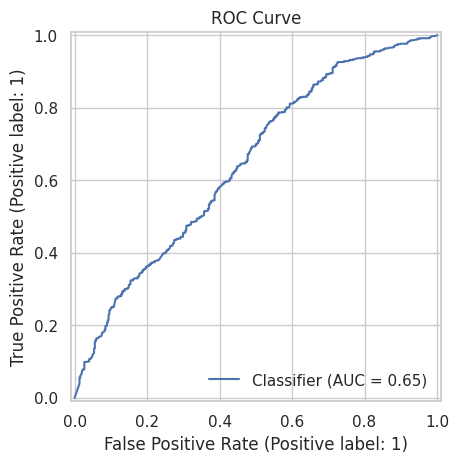


Top 10 Important Features for Prediction:
UnitPrice    0.462570
Quantity     0.287213
Month_sin    0.154234
Month_cos    0.095983
dtype: float64


In [ ]:
# --- Appended plot cell 13 from your notebook ---
try:
  # Full ready-to-run pipeline for "Will the Customer Return?"
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns

  from sklearn.model_selection import train_test_split
  from sklearn.ensemble import RandomForestClassifier
  from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, RocCurveDisplay

  # --- 0. Optional reproducibility ----
  RANDOM_STATE = 42
  np.random.seed(RANDOM_STATE)

  print("--- 4. Predictive Modeling: Will the Customer Return? ---")

  # ---- A. FEATURE ENGINEERING (Based on FIRST purchase only) ----
  # 1) Sort and pick first purchase
  df_sorted = df_sales.sort_values(['CustomerID', 'InvoiceDate'])
  first_purchase = df_sorted.groupby('CustomerID', as_index=False).first()

  # 2) Target: repeat (Frequency > 1) using rfm['Frequency']
  #    Make sure rfm index or column is aligned to CustomerID
  #    We map using CustomerID -> boolean then to int
  customer_targets = (rfm['Frequency'] > 1).astype(int)
  # If rfm is indexed by CustomerID, mapping works; if not, ensure rfm has CustomerID column
  if 'CustomerID' in rfm.columns:
      customer_targets = rfm.set_index('CustomerID')['Frequency'].gt(1).astype(int)

  first_purchase['IsRepeatCustomer'] = first_purchase['CustomerID'].map(customer_targets).fillna(0).astype(int)

  # 3) Select features (first item features + metadata)
  model_data = first_purchase[['UnitPrice', 'Quantity', 'Country', 'InvoiceDate', 'IsRepeatCustomer']].copy()

  # Extract Month from InvoiceDate robustly
  # Handle cases where InvoiceDate is Period, datetime, string, or int
  if isinstance(model_data['InvoiceDate'].dtype, pd.PeriodDtype):
      # Period -> month number
      model_data['Month'] = model_data['InvoiceDate'].dt.month
  elif pd.api.types.is_datetime64_any_dtype(model_data['InvoiceDate']):
      model_data['Month'] = model_data['InvoiceDate'].dt.month
  else:
      # Try to coerce strings to datetime first, then month; otherwise try direct int cast; fallback to string
      try:
          model_data['InvoiceDate'] = pd.to_datetime(model_data['InvoiceDate'])
          model_data['Month'] = model_data['InvoiceDate'].dt.month
      except Exception:
          # Last resort: if a 'Month' column already exists or InvoiceDate stores month ints
          if 'Month' in model_data.columns:
              try:
                  model_data['Month'] = model_data['Month'].astype(int)
              except Exception:
                  model_data['Month'] = model_data['Month'].astype(str)
          else:
              # Try convert InvoiceDate to int (e.g., it might already be month)
              try:
                  model_data['Month'] = model_data['InvoiceDate'].astype(int)
              except Exception:
                  # fallback: convert to string (will be dummy-encoded below)
                  model_data['Month'] = model_data['InvoiceDate'].astype(str)

  # Drop the raw InvoiceDate (no longer needed)
  model_data.drop(columns=['InvoiceDate'], inplace=True)

  # Optional: create cyclical month features (captures seasonality better than raw integer)
  # Only do this if Month is numeric (1-12)
  if pd.api.types.is_integer_dtype(model_data['Month']) or pd.api.types.is_float_dtype(model_data['Month']):
      # Ensure valid month values between 1 and 12; if not, skip cyclical transform
      if model_data['Month'].between(1, 12).all():
          model_data['Month_sin'] = np.sin(2 * np.pi * model_data['Month'] / 12)
          model_data['Month_cos'] = np.cos(2 * np.pi * model_data['Month'] / 12)
          # We can drop the raw Month number if we prefer purely cyclical
          model_data.drop(columns=['Month'], inplace=True)
      else:
          # If Month values are not 1-12, convert to string and dummy encode below
          model_data['Month'] = model_data['Month'].astype(str)

  # ---- B. ENCODE CATEGORICALS ----
  # Encode Country + any remaining object columns
  # Convert object (string) columns to dummies
  categorical_cols = model_data.select_dtypes(include=['object', 'category']).columns.tolist()
  if 'IsRepeatCustomer' in categorical_cols:
      categorical_cols.remove('IsRepeatCustomer')

  if categorical_cols:
      model_data = pd.get_dummies(model_data, columns=categorical_cols, drop_first=True)

  # At this point model_data should be numeric + IsRepeatCustomer
  # Check for any remaining non-numeric columns and drop them (or raise)
  non_numeric = model_data.select_dtypes(exclude=[np.number]).columns.tolist()
  if non_numeric:
      print("Warning: Dropping non-numeric columns before modeling:", non_numeric)
      model_data.drop(columns=non_numeric, inplace=True)

  # ---- C. PREPARE X/y and TRAIN/TEST SPLIT ----
  X = model_data.drop('IsRepeatCustomer', axis=1)
  y = model_data['IsRepeatCustomer']

  print("\nFeature dtypes (preview):")
  print(X.dtypes.head(20))
  print(f"\nDataset size: {X.shape}, Positive class ratio: {y.mean():.3f}")

  # Train/test split
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y if y.nunique() > 1 else None
  )

  # ---- D. MODEL TRAINING (RandomForest) ----
  rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced')
  try:
      rf_model.fit(X_train, y_train)
  except Exception as e:
      raise RuntimeError("Model fitting failed. Check that all X columns are numeric and y contains at least two classes.") from e

  # ---- E. EVALUATION ----
  y_pred = rf_model.predict(X_test)
  # If predict_proba is available:
  if hasattr(rf_model, "predict_proba"):
      y_prob = rf_model.predict_proba(X_test)[:, 1]
  else:
      # fallback to decision_function or predictions
      try:
          y_prob = rf_model.decision_function(X_test)
          # scale to [0,1]
          y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min())
      except Exception:
          y_prob = y_pred  # not ideal, but avoids crash

  print("\nClassification Report:")
  print(classification_report(y_test, y_pred, digits=4))

  # ROC-AUC (only if there is more than one class present in y_test)
  if len(np.unique(y_test)) > 1:
      try:
          roc_auc = roc_auc_score(y_test, y_prob)
          print(f"ROC-AUC Score: {roc_auc:.4f}")
      except Exception as e:
          print("ROC-AUC could not be calculated:", str(e))
  else:
      print("ROC-AUC not calculated: only one class present in y_test.")

  # Confusion matrix plot
  plt.figure(figsize=(6,5))
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.title("Confusion Matrix: Predict Repeat Customer")
  plt.ylabel('Actual')
  plt.xlabel('Predicted')
  plt.show()

  # ROC curve plot (if possible)
  if len(np.unique(y_test)) > 1:
      try:
          RocCurveDisplay.from_predictions(y_test, y_prob)
          plt.title("ROC Curve")
          plt.show()
      except Exception as e:
          print("Could not plot ROC curve:", str(e))

  # Feature importances
  importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
  print("\nTop 10 Important Features for Prediction:")
  print(importances.head(10))

except Exception as e:
    print("Appended plot cell 13 failed with:", e)


--- 1. PREPARING DATA FOR MODELING ---
Training Shape: (3036, 39)
Testing Shape:  (1302, 39)

--- 2. TRAINING THE MODEL ---
Model trained successfully.

--- 3. PERFORMANCE VALIDATION REPORT ---
Accuracy:  0.6590
Precision: 0.7373
Recall:    0.7724
F1 Score:  0.7544
ROC-AUC:   0.6321


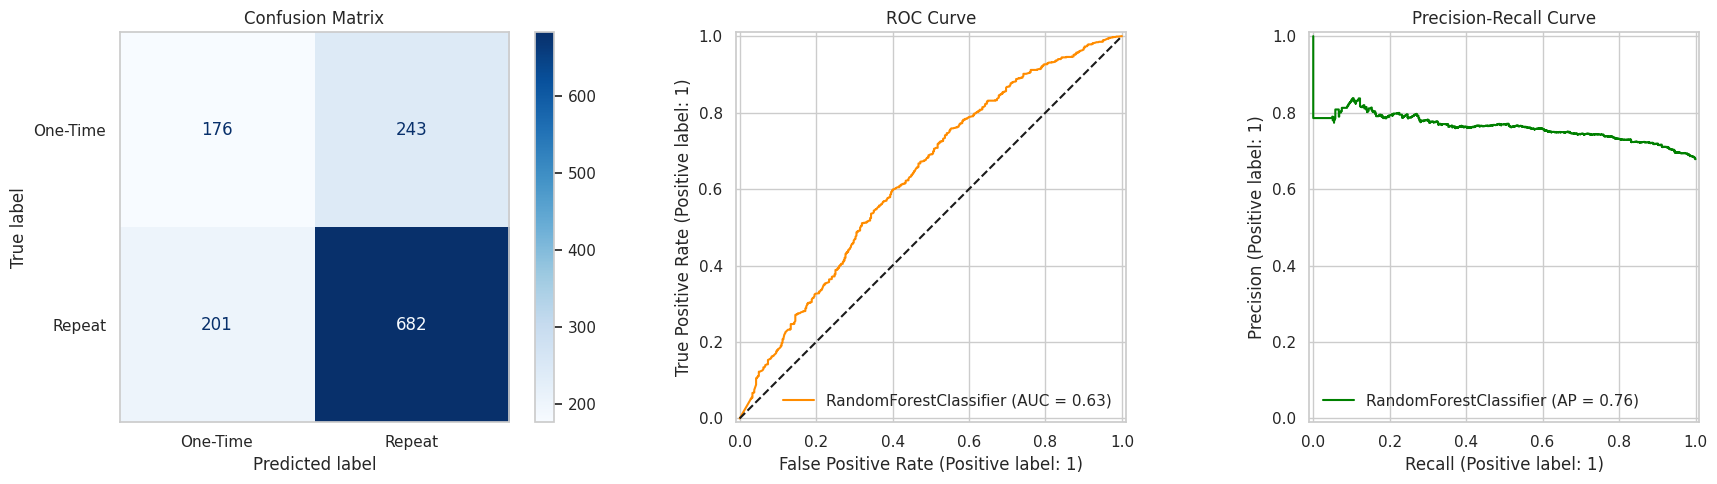


--- 4. CROSS-VALIDATION (Robustness Check) ---
5-Fold Cross-Validation AUC: 0.6505 (+/- 0.0423)


In [ ]:
# --- Appended plot cell 14 from your notebook ---
try:
  # ==========================================
  # PART 9: PREDICTIVE MODELING (FIXED)
  # ==========================================
  from sklearn.model_selection import train_test_split, cross_val_score
  from sklearn.ensemble import RandomForestClassifier
  from sklearn.metrics import (
      classification_report, roc_auc_score, confusion_matrix,
      ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
      accuracy_score, precision_score, recall_score, f1_score
  )
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns

  print("--- 1. PREPARING DATA FOR MODELING ---")

  # A. Feature Engineering (First Purchase Only)
  # We sort by Customer and Date to get the very first transaction for every customer
  df_sorted = df_sales.sort_values(['CustomerID', 'InvoiceDate'])
  first_purchase = df_sorted.groupby('CustomerID').first().reset_index()

  # B. Target Variable: Did they return?
  first_purchase['IsRepeatCustomer'] = (rfm['Frequency'].values > 1).astype(int)

  # C. Select Features & Encode
  model_data = first_purchase[['UnitPrice', 'Quantity', 'Country', 'IsRepeatCustomer']].copy()

  # --- THE FIX IS HERE ---
  # We deliberately re-create the 'Month' column as a simple integer (1-12)
  # This removes any "Period" formatting that causes the crash
  model_data['Month'] = first_purchase['InvoiceDate'].dt.month

  # One-Hot Encoding for 'Country'
  model_data = pd.get_dummies(model_data, columns=['Country'], drop_first=True)

  # D. Define X and y
  X = model_data.drop('IsRepeatCustomer', axis=1)
  y = model_data['IsRepeatCustomer']

  # E. Train/Test Split (70/30)
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

  print(f"Training Shape: {X_train.shape}")
  print(f"Testing Shape:  {X_test.shape}")


  print("\n--- 2. TRAINING THE MODEL ---")
  # Initialize and Train Random Forest
  rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
  rf_model.fit(X_train, y_train)
  print("Model trained successfully.")


  print("\n--- 3. PERFORMANCE VALIDATION REPORT ---")

  # Generate Predictions
  y_pred = rf_model.predict(X_test)
  y_prob = rf_model.predict_proba(X_test)[:, 1]

  # Calculate Metrics
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_prob)

  print(f"Accuracy:  {acc:.4f}")
  print(f"Precision: {prec:.4f}")
  print(f"Recall:    {rec:.4f}")
  print(f"F1 Score:  {f1:.4f}")
  print(f"ROC-AUC:   {auc:.4f}")

  # Visualizations
  fig, axes = plt.subplots(1, 3, figsize=(18, 5))

  # Plot A: Confusion Matrix
  cm = confusion_matrix(y_test, y_pred)
  ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['One-Time', 'Repeat']).plot(ax=axes[0], cmap='Blues')
  axes[0].set_title('Confusion Matrix')
  axes[0].grid(False)

  # Plot B: ROC Curve
  RocCurveDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[1], color='darkorange')
  axes[1].set_title('ROC Curve')
  axes[1].plot([0, 1], [0, 1], 'k--')
  axes[1].grid(True)

  # Plot C: Precision-Recall Curve
  PrecisionRecallDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[2], color='green')
  axes[2].set_title('Precision-Recall Curve')
  axes[2].grid(True)

  plt.tight_layout()
  plt.show()

  print("\n--- 4. CROSS-VALIDATION (Robustness Check) ---")
  cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='roc_auc')
  print(f"5-Fold Cross-Validation AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")
except Exception as e:
    print("Appended plot cell 14 failed with:", e)


--- 1. LIBRARIES LOADED ---

--- 2. DATA LOADING & CLEANING ---
Data Loaded Successfully. Shape: (541909, 8)
Duplicates Removed. New Shape: (536641, 8)
Cleaned Sales Data (Positive Qty & Price): (392692, 8)

--- 3. FEATURE ENGINEERING ---
Features Created: TotalAmount, Year, Month, DayOfWeek, Hour

--- 4. DATA DIAGNOSTICS (Distributions & Outliers) ---


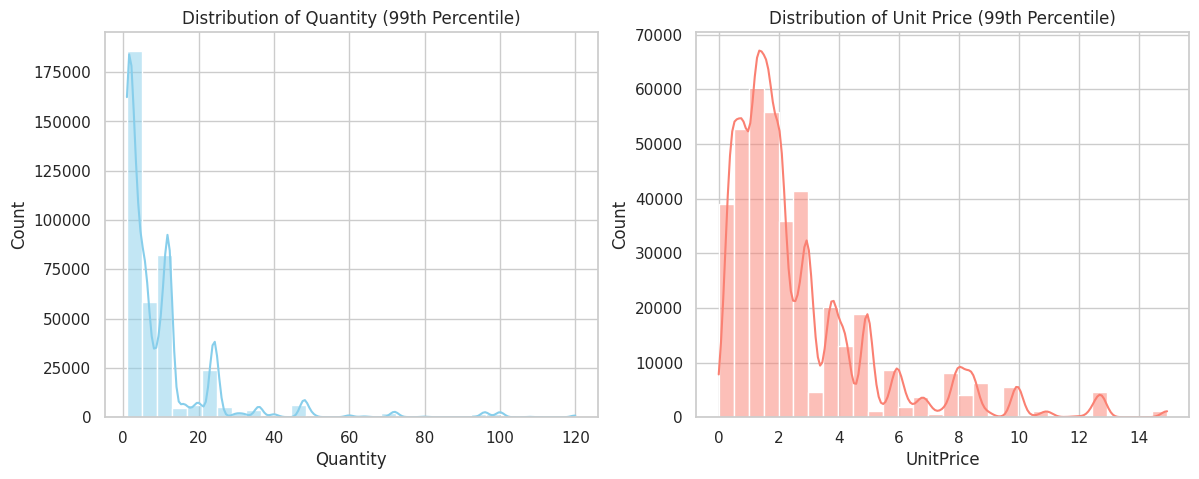


--- 5. RFM SEGMENTATION & ANALYSIS ---


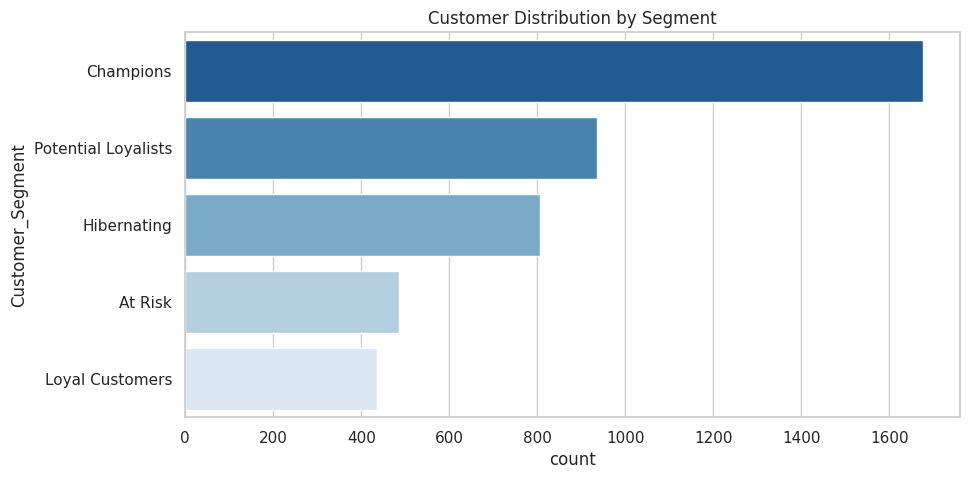

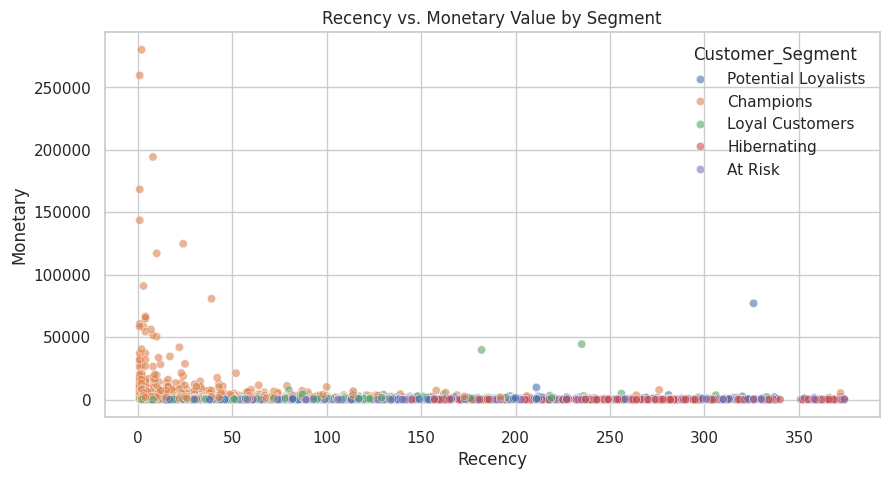


--- 6. HYPOTHESIS TESTING ---
H1 (Freq vs Monetary): P-value = 4.5169e-26 | Significant? True
H3 (Weekly Seasonality): P-value = 3.1481e-01 | Significant? False
H4 (Intl vs UK Value): P-value = 9.2862e-22 | Significant? True
H5 (Cancellations by Country): P-value = 1.4082e-116 | Significant? True

--- 7. CLUSTERING MODEL COMPARISON (K-Means vs Others) ---
K-Means Silhouette:       0.3398
Hierarchical Silhouette:  0.3032
GMM Silhouette:           0.2870


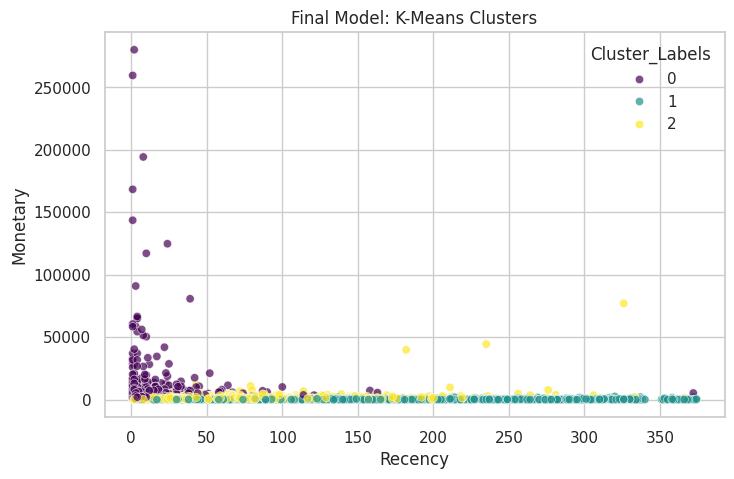


--- 8. ADDITIONAL ANALYSES (Time-Series, Returns, Cohorts) ---
A. Generating Time-Series Decomposition...


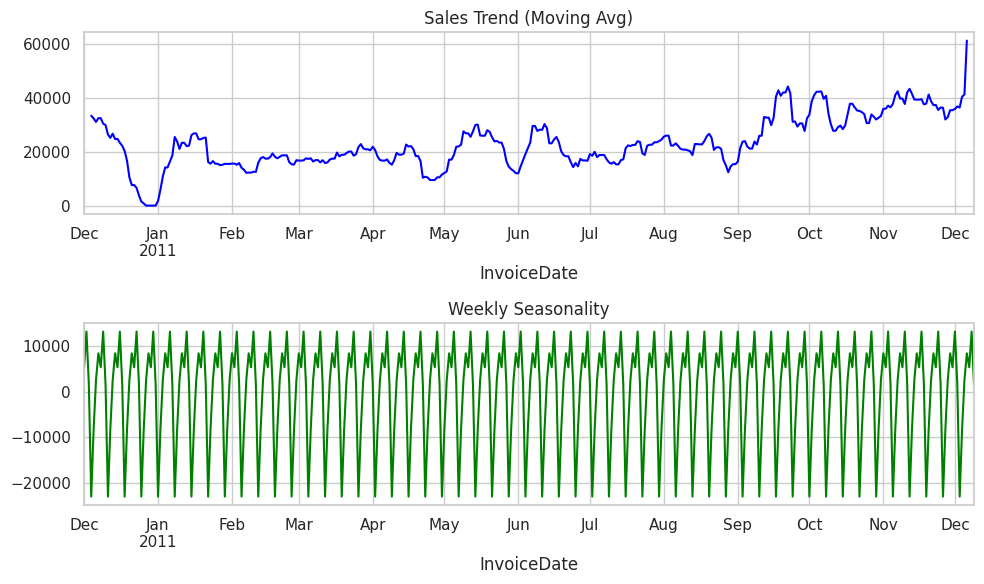

B. Calculating Return Rates...


,Total_Sold,Total_Returned,Return_Rate
Description,,,
check,1217,13247,0.915860
damaged,192,1824,0.904762
wrongly coded 20713,800,1000,0.555556
?,8112,9496,0.539300
incorrectly credited C550456 see 47,1300,1300,0.500000


C. Generating Cohort Heatmap...


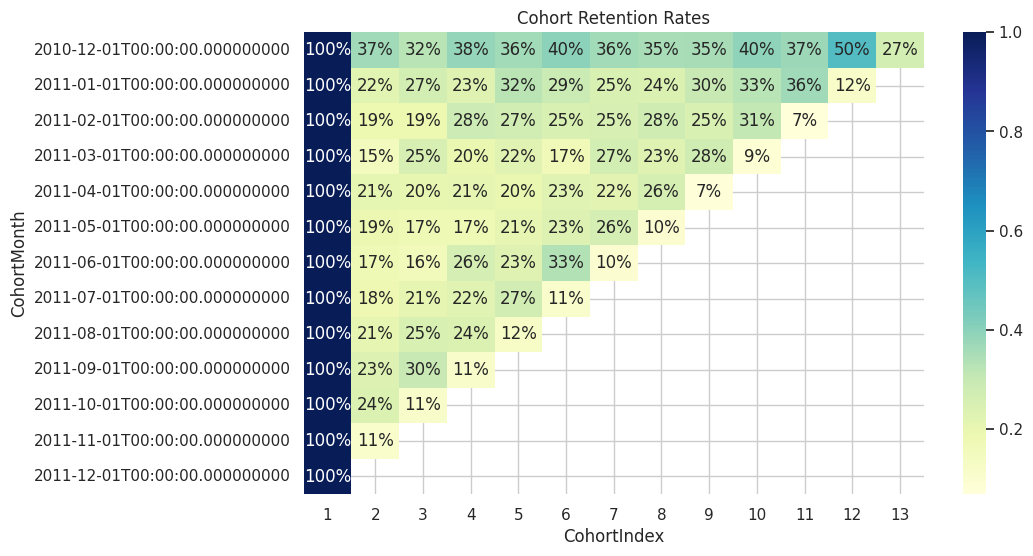


--- 9. PREDICTIVE MODELING (Will Customer Return?) ---
--- PERFORMANCE REPORT ---
Accuracy:  0.6590
Precision: 0.7373
Recall:    0.7724
ROC-AUC:   0.6321


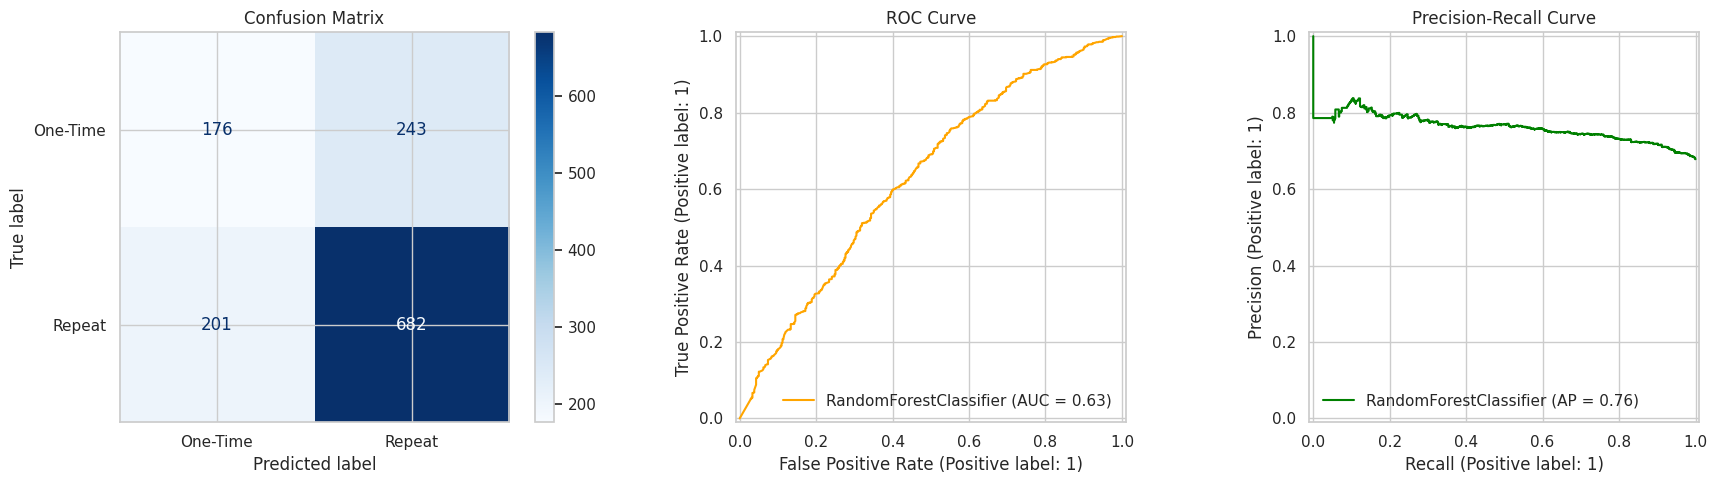


--- 5-FOLD CROSS-VALIDATION ---
Mean AUC: 0.6505 (+/- 0.0423)
Conclusion: Model is STABLE.


In [ ]:
# --- Appended plot cell 15 from your notebook ---
try:
  # =============================================================================
  # MASTER PROJECT CODE: ONLINE RETAIL ANALYSIS (TEAM 1)
  # =============================================================================

  # --- 1. LIBRARIES & CONFIGURATION ---
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  import seaborn as sns

  import datetime as dt
  import scipy.stats as stats
  from statsmodels.tsa.seasonal import seasonal_decompose

  # Machine Learning Imports
  from sklearn.preprocessing import StandardScaler
  from sklearn.cluster import KMeans, AgglomerativeClustering
  from sklearn.mixture import GaussianMixture
  from sklearn.metrics import silhouette_score, davies_bouldin_score
  from sklearn.model_selection import train_test_split, cross_val_score
  from sklearn.ensemble import RandomForestClassifier
  from sklearn.metrics import (
      classification_report, roc_auc_score, confusion_matrix,
      ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
      accuracy_score, precision_score, recall_score, f1_score
  )

  # Settings
  sns.set(style="whitegrid")
  pd.set_option('display.max_columns', None)

  print("--- 1. LIBRARIES LOADED ---")


  # --- 2. DATA LOADING & CLEANING ---
  print("\n--- 2. DATA LOADING & CLEANING ---")
  try:
      # [cite_start]Load dataset [cite: 20, 22]
      df = pd.read_excel('Online Retail.xlsx')
      print(f"Data Loaded Successfully. Shape: {df.shape}")
  except FileNotFoundError:
      print("Error: 'Online Retail.xlsx' not found. Please upload the file.")

  # [cite_start]A. Remove Duplicates [cite: 33]
  df.drop_duplicates(inplace=True)
  print(f"Duplicates Removed. New Shape: {df.shape}")

  # [cite_start]B. Handle Missing Values (Focusing on CustomerID) [cite: 32]
  df_clean = df.dropna(subset=['CustomerID'])

  # C. Filter for Sales Analysis (Positive Quantity & Price)
  # We keep 'df' (raw) for Return Analysis later, but use 'df_sales' for general analysis
  df_sales = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)].copy()
  print(f"Cleaned Sales Data (Positive Qty & Price): {df_sales.shape}")


  # --- 3. FEATURE ENGINEERING ---
  print("\n--- 3. FEATURE ENGINEERING ---")
  # [cite_start]Monetary Value [cite: 41]
  df_sales['TotalAmount'] = df_sales['Quantity'] * df_sales['UnitPrice']

  # Date Features
  df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])
  df_sales['Year'] = df_sales['InvoiceDate'].dt.year
  df_sales['Month'] = df_sales['InvoiceDate'].dt.month
  df_sales['DayOfWeek'] = df_sales['InvoiceDate'].dt.day_name()
  df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour
  print("Features Created: TotalAmount, Year, Month, DayOfWeek, Hour")


  # --- 4. DATA DIAGNOSTICS & DISTRIBUTIONS ---
  print("\n--- 4. DATA DIAGNOSTICS (Distributions & Outliers) ---")
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Quantity Distribution (Clipped for visibility - 99th percentile)
  q_99 = df_sales['Quantity'].quantile(0.99)
  sns.histplot(df_sales[df_sales['Quantity'] <= q_99]['Quantity'], bins=30, kde=True, ax=axes[0], color='skyblue')
  axes[0].set_title('Distribution of Quantity (99th Percentile)')

  # UnitPrice Distribution (Clipped for visibility - 99th percentile)
  p_99 = df_sales['UnitPrice'].quantile(0.99)
  sns.histplot(df_sales[df_sales['UnitPrice'] <= p_99]['UnitPrice'], bins=30, kde=True, ax=axes[1], color='salmon')
  axes[1].set_title('Distribution of Unit Price (99th Percentile)')
  plt.show()


  # --- 5. RFM SEGMENTATION ---
  print("\n--- 5. RFM SEGMENTATION & ANALYSIS ---")
  latest_date = df_sales['InvoiceDate'].max() + dt.timedelta(days=1)

  # [cite_start]Calculate R, F, M [cite: 41]
  rfm = df_sales.groupby('CustomerID').agg({
      'InvoiceDate': lambda x: (latest_date - x.max()).days, # Recency
      'InvoiceNo': 'nunique',                                # Frequency
      'TotalAmount': 'sum'                                   # Monetary
  }).rename(columns={'InvoiceDate': 'Recency', 'InvoiceNo': 'Frequency', 'TotalAmount': 'Monetary'})

  # Scoring (Quartiles)
  r_labels = range(4, 0, -1) # Lower Recency is better (4)
  f_labels = range(1, 5)     # Higher Frequency is better (4)
  m_labels = range(1, 5)     # Higher Monetary is better (4)

  rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels)
  rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels)
  rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=m_labels)

  # RFM Segment & Labels
  rfm['RFM_Sum'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

  def segment_customer(df):
      if df['RFM_Sum'] >= 9: return 'Champions'
      elif df['RFM_Sum'] >= 8: return 'Loyal Customers'
      elif df['RFM_Sum'] >= 6: return 'Potential Loyalists'
      elif df['RFM_Sum'] >= 5: return 'At Risk'
      else: return 'Hibernating'

  rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

  # Visualize Segments
  plt.figure(figsize=(10, 5))
  sns.countplot(y='Customer_Segment', data=rfm, order=rfm['Customer_Segment'].value_counts().index, palette='Blues_r')
  plt.title('Customer Distribution by Segment')
  plt.show()

  # Scatter Plot: Recency vs Monetary
  plt.figure(figsize=(10, 5))
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Customer_Segment', palette='deep', alpha=0.6)
  plt.title('Recency vs. Monetary Value by Segment')
  plt.show()


  # --- 6. HYPOTHESIS TESTING (Inferential Statistics) ---
  print("\n--- 6. HYPOTHESIS TESTING ---")

  # [cite_start]H1: High Freq vs Low Freq Monetary Value [cite: 51]
  q75 = rfm['Frequency'].quantile(0.75)
  q25 = rfm['Frequency'].quantile(0.25)
  high_freq = rfm[rfm['Frequency'] >= q75]['Monetary']
  low_freq = rfm[rfm['Frequency'] <= q25]['Monetary']
  t_stat_h1, p_val_h1 = stats.ttest_ind(high_freq, low_freq, equal_var=False)
  print(f"H1 (Freq vs Monetary): P-value = {p_val_h1:.4e} | Significant? {p_val_h1 < 0.05}")

  # [cite_start]H3: Weekly Transaction Pattern (ANOVA) [cite: 63]
  daily_transactions = df_sales.groupby(['InvoiceDate', 'DayOfWeek'])['InvoiceNo'].nunique().reset_index()
  groups_h3 = [daily_transactions[daily_transactions['DayOfWeek'] == day]['InvoiceNo'] for day in daily_transactions['DayOfWeek'].unique()]
  f_stat_h3, p_val_h3 = stats.f_oneway(*groups_h3)
  print(f"H3 (Weekly Seasonality): P-value = {p_val_h3:.4e} | Significant? {p_val_h3 < 0.05}")

  # [cite_start]H4: UK vs International Order Value (T-Test) [cite: 68]
  invoice_vals = df_sales.groupby(['InvoiceNo', 'Country'])['TotalAmount'].sum().reset_index()
  uk_vals = invoice_vals[invoice_vals['Country'] == 'United Kingdom']['TotalAmount']
  intl_vals = invoice_vals[invoice_vals['Country'] != 'United Kingdom']['TotalAmount']
  t_stat_h4, p_val_h4 = stats.ttest_ind(intl_vals, uk_vals, equal_var=False)
  print(f"H4 (Intl vs UK Value): P-value = {p_val_h4:.4e} | Significant? {p_val_h4 < 0.05}")

  # [cite_start]H5: Geographic Variation in Cancellations (Chi-Square) [cite: 76]
  df_h5 = df.copy() # Use raw df to see negative quantities
  df_h5['IsCancelled'] = np.where(df_h5['Quantity'] < 0, 1, 0)
  top_countries = df_h5['Country'].value_counts().head(5).index
  df_h5_top = df_h5[df_h5['Country'].isin(top_countries)]
  contingency = pd.crosstab(df_h5_top['Country'], df_h5_top['IsCancelled'])
  chi2, p_val_h5, dof, exp = stats.chi2_contingency(contingency)
  print(f"H5 (Cancellations by Country): P-value = {p_val_h5:.4e} | Significant? {p_val_h5 < 0.05}")


  # --- 7. CLUSTERING MODEL COMPARISON ---
  print("\n--- 7. CLUSTERING MODEL COMPARISON (K-Means vs Others) ---")
  # Preprocessing
  rfm_log = np.log(rfm[['Recency', 'Frequency', 'Monetary']])
  scaler = StandardScaler()
  rfm_scaled = scaler.fit_transform(rfm_log)
  K = 3 # Chosen K

  # Models
  kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
  agglo = AgglomerativeClustering(n_clusters=K)
  gmm = GaussianMixture(n_components=K, random_state=42)

  # Fit & Predict
  labels_km = kmeans.fit_predict(rfm_scaled)
  labels_agg = agglo.fit_predict(rfm_scaled)
  labels_gmm = gmm.fit_predict(rfm_scaled)

  # Evaluation (Silhouette)
  print(f"K-Means Silhouette:       {silhouette_score(rfm_scaled, labels_km):.4f}")
  print(f"Hierarchical Silhouette:  {silhouette_score(rfm_scaled, labels_agg):.4f}")
  print(f"GMM Silhouette:           {silhouette_score(rfm_scaled, labels_gmm):.4f}")

  # Visualize K-Means Result
  rfm['Cluster_Labels'] = labels_km
  plt.figure(figsize=(8, 5))
  sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster_Labels', palette='viridis', alpha=0.7)
  plt.title('Final Model: K-Means Clusters')
  plt.show()


  # --- 8. ADDITIONAL ANALYSES ---
  print("\n--- 8. ADDITIONAL ANALYSES (Time-Series, Returns, Cohorts) ---")

  # A. Time-Series (Daily -> Weekly Decomp)
  print("A. Generating Time-Series Decomposition...")
  # Use 'D' (Daily) to allow decomposition on 1 year data
  daily_sales = df_sales.set_index('InvoiceDate').resample('D')['TotalAmount'].sum().fillna(0)
  decomposition = seasonal_decompose(daily_sales, model='additive', period=7) # Period=7 for weekly patterns
  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
  decomposition.trend.plot(ax=ax1, title='Sales Trend (Moving Avg)', color='blue')
  decomposition.seasonal.plot(ax=ax2, title='Weekly Seasonality', color='green')
  plt.tight_layout()
  plt.show()

  # [cite_start]B. Return Rates [cite: 35]
  print("B. Calculating Return Rates...")
  product_stats = df.groupby('Description').agg({
      'Quantity': [('Total_Sold', lambda x: x[x > 0].sum()), ('Total_Returned', lambda x: abs(x[x < 0].sum()))]
  })
  product_stats.columns = product_stats.columns.droplevel()
  product_stats['Return_Rate'] = product_stats['Total_Returned'] / (product_stats['Total_Sold'] + product_stats['Total_Returned'])
  display(product_stats[product_stats['Total_Sold'] > 50].sort_values('Return_Rate', ascending=False).head(5))

  # C. Cohort Analysis (Retention)
  print("C. Generating Cohort Heatmap...")
  df_cohort = df_sales.copy()
  df_cohort['InvoiceMonth'] = df_cohort['InvoiceDate'].apply(lambda x: dt.datetime(x.year, x.month, 1))
  df_cohort['CohortMonth'] = df_cohort.groupby('CustomerID')['InvoiceMonth'].transform('min')
  df_cohort['CohortIndex'] = ((df_cohort['InvoiceMonth'].dt.year - df_cohort['CohortMonth'].dt.year) * 12 +
                            (df_cohort['InvoiceMonth'].dt.month - df_cohort['CohortMonth'].dt.month) + 1)
  cohort_count = df_cohort.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index().pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')
  retention = cohort_count.divide(cohort_count.iloc[:,0], axis=0)
  plt.figure(figsize=(10, 6))
  sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
  plt.title('Cohort Retention Rates')
  plt.show()


  # --- 9. PREDICTIVE MODELING (Classification) ---
  print("\n--- 9. PREDICTIVE MODELING (Will Customer Return?) ---")

  # A. Feature Engineering (First Purchase Only)
  df_sorted = df_sales.sort_values(['CustomerID', 'InvoiceDate'])
  first_purchase = df_sorted.groupby('CustomerID').first().reset_index()

  # B. Target: Is Repeat Customer?
  first_purchase['IsRepeatCustomer'] = (rfm['Frequency'].values > 1).astype(int)

  # C. Prep Data & Encode
  model_data = first_purchase[['UnitPrice', 'Quantity', 'Country', 'Month', 'IsRepeatCustomer']].copy()
  model_data = pd.get_dummies(model_data, columns=['Country'], drop_first=True)

  X = model_data.drop('IsRepeatCustomer', axis=1)
  y = model_data['IsRepeatCustomer']

  # D. Train/Test Split
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

  # E. Train Model
  rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
  rf_model.fit(X_train, y_train)

  # F. Performance Validation
  y_pred = rf_model.predict(X_test)
  y_prob = rf_model.predict_proba(X_test)[:, 1]

  print("--- PERFORMANCE REPORT ---")
  print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
  print(f"Precision: {precision_score(y_test, y_pred):.4f}")
  print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
  print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

  # G. Visual Validation
  fig, axes = plt.subplots(1, 3, figsize=(18, 5))
  ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[0], cmap='Blues', display_labels=['One-Time', 'Repeat'])
  axes[0].set_title('Confusion Matrix')
  RocCurveDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[1], color='orange')
  axes[1].set_title('ROC Curve')
  PrecisionRecallDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[2], color='green')
  axes[2].set_title('Precision-Recall Curve')
  plt.tight_layout()
  plt.show()

  # H. Cross-Validation (Robustness)
  print("\n--- 5-FOLD CROSS-VALIDATION ---")
  cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='roc_auc')
  print(f"Mean AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")
  if cv_scores.std() < 0.05:
      print("Conclusion: Model is STABLE.")
  else:
      print("Conclusion: Model is UNSTABLE.")
except Exception as e:
    print("Appended plot cell 15 failed with:", e)
